In [1]:
from pathlib import Path

base = Path("/kaggle/input")

print("Attached inputs:")
for item in sorted(base.iterdir()):
    print(f"\n{'DIR ' if item.is_dir() else 'FILE'}: {item}")

    if item.is_dir():
        for child in sorted(item.iterdir())[:40]:
            print(f"    {'DIR ' if child.is_dir() else 'FILE'}: {child.name}")

Attached inputs:

DIR : /kaggle/input/datasets
    DIR : preethivardhankgl


In [2]:
!nvidia-smi

import sys, torch, numpy, pandas, sklearn, matplotlib
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

Thu Oct 29 09:13:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             16W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
%pip install -q gdown
import gdown
print("gdown:", gdown.__version__)

Note: you may need to restart the kernel to use updated packages.
gdown: 5.2.2


In [4]:
from pathlib import Path
import shutil, zipfile

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
PROJECT_DIR = WORK_ROOT / "ECERC_complete"
EXTRACT_DIR = WORK_ROOT / "_ecerc_archive_extract"

def valid_project_roots(base: Path):
    roots = []
    if not base.exists():
        return roots
    for p in base.rglob("auto_tune.py"):
        root = p.parent
        if (
            (root / "PROJECT_STATUS.md").is_file()
            and (root / "SOP_corrections.md").is_file()
            and (root / "report.py").is_file()
            and (root / "MELD" / "train.py").is_file()
            and (root / "IEMOCAP" / "train.py").is_file()
        ):
            roots.append(root)
    # Stable unique paths
    return list(dict.fromkeys(roots))

archives = []
for z in INPUT_ROOT.rglob("*.zip"):
    try:
        with zipfile.ZipFile(z) as archive:
            names = archive.namelist()
            has_runner = any(n.endswith("ECERC_complete/auto_tune.py") for n in names)
            has_status = any(n.endswith("ECERC_complete/PROJECT_STATUS.md") for n in names)
            has_corrections = any(n.endswith("ECERC_complete/SOP_corrections.md") for n in names)
            if has_runner and has_status and has_corrections:
                archives.append(z)
    except (zipfile.BadZipFile, OSError):
        pass

if archives:
    # Prefer the named final_v3 archive if more than one matching archive was added.
    archives.sort(key=lambda p: ("final_v3" not in p.name.lower(), p.name.lower()))
    selected_zip = archives[0]
    print("Using project archive:", selected_zip)
    shutil.rmtree(EXTRACT_DIR, ignore_errors=True)
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(selected_zip) as archive:
        archive.extractall(EXTRACT_DIR)
    roots = valid_project_roots(EXTRACT_DIR)
else:
    # Fallback for a Kaggle input where the ZIP has already been extracted.
    roots = valid_project_roots(INPUT_ROOT)

if not roots:
    raise FileNotFoundError(
        "Could not find the CURRENT project. Add ECERC_project_final_v3(1).zip as a Kaggle input, "
        "then rerun this cell. It requires PROJECT_STATUS.md, SOP_corrections.md and report.py."
    )

source_root = roots[0]
if PROJECT_DIR.exists():
    shutil.rmtree(PROJECT_DIR)
shutil.copytree(source_root, PROJECT_DIR)
print("Writable project copy:", PROJECT_DIR)
print("Project markers:", (PROJECT_DIR / "PROJECT_STATUS.md").exists(),
      (PROJECT_DIR / "SOP_corrections.md").exists(), (PROJECT_DIR / "report.py").exists())
print("Top-level files:", sorted(p.name for p in PROJECT_DIR.iterdir())[:30])

Writable project copy: /kaggle/working/ECERC_complete
Project markers: True True True
Top-level files: ['.dockerignore', 'Dockerfile', 'IEMOCAP', 'MELD', 'OS_info.txt', 'PROJECT_STATUS.md', 'README.md', 'README_ADDITIONS.md', 'SOP_corrections.md', 'auto_tune.py', 'data', 'docker_check.sh', 'download_data.py', 'report.py', 'requirement.yml', 'requirements.txt', 'run_ablation.sh', 'run_final.sh', 'run_span_sweep.sh', 'summarize_logs.py', 'tests']


In [5]:
%cd /kaggle/working/ECERC_complete
!python -m compileall -q .
!python tests/run_tests.py

/kaggle/working/ECERC_complete
test_authors_gamma_constant_in_train_py_matches_official_default (__main__.TestLoss.test_authors_gamma_constant_in_train_py_matches_official_default) ... /kaggle/working/ECERC_complete/tests/run_tests.py:88: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/ECERC_complete/tests/reference/official_MELD_loss.py' mode='r' encoding='utf-8'>
  g_official = re.search(r'class Loss.*?def __init__\(self, gamma=([\d.]+)', open(os.path.join(REF, 'official_%s_loss.py' % ds)).read(), re.S).group(1)
/kaggle/working/ECERC_complete/tests/run_tests.py:88: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/ECERC_complete/tests/reference/official_IEMOCAP_loss.py' mode='r' encoding='utf-8'>
  g_official = re.search(r'class Loss.*?def __init__\(self, gamma=([\d.]+)', open(os.path.join(REF, 'official_%s_loss.py' % ds)).read(), re.S).group(1)
ok
test_authors_loss_class_is_byte_identical_to_official (__main__.TestLoss.test_authors_loss_

In [6]:
%cd /kaggle/working/ECERC_complete
!python tests/smoke_test.py

/kaggle/working/ECERC_complete
test_auto_tune_final_matrix_and_report (__main__.TestPipeline.test_auto_tune_final_matrix_and_report) ... /kaggle/working/ECERC_complete/tests/smoke_test.py:78: ResourceWarning: unclosed file <_io.TextIOWrapper name='/tmp/ecerc_smoke_hhyauj_o/tuning_results/MELD/final_results.json' mode='r' encoding='utf-8'>
  res = json.load(open(os.path.join(out, 'final_results.json')))
/kaggle/working/ECERC_complete/tests/smoke_test.py:94: ResourceWarning: unclosed file <_io.TextIOWrapper name='/tmp/ecerc_smoke_hhyauj_o/tuning_results/MELD/status.json' mode='r' encoding='utf-8'>
  st = json.load(open(os.path.join(out, 'status.json')))
/kaggle/working/ECERC_complete/tests/smoke_test.py:98: ResourceWarning: unclosed file <_io.TextIOWrapper name='/tmp/ecerc_smoke_hhyauj_o/tuning_results/MELD/final_results.csv' mode='r' encoding='utf-8'>
  rows = list(csv.DictReader(open(os.path.join(out, 'final_results.csv'))))
/kaggle/working/ECERC_complete/tests/smoke_test.py:102: Resou

In [7]:
%cd /kaggle/working/ECERC_complete
!python download_data.py

/kaggle/working/ECERC_complete
Retrieving folder contents
Retrieving folder 1JBRRM9hpAp065himXAmF_R9O_oyhPx85 iemocap
Processing file 1vbgQ78Pzil6trugnPmgqP8q7j-fAweCj iemocap_emotion_features_roberta.pkl
Processing file 1CQ32t7FPvQU7i0S7h6fGUClPxwvQW9Qv iemocap_emotion_semantic_features_roberta.pkl
Processing file 1RV-V6aiUzENUy97XskKqgm_bCJATpapS IEMOCAP_features.pkl
Processing file 1tVWmb5HB0YOu3uAkIvTvSYEYEja8XK-V iemocap_semantic_features_roberta.pkl
Retrieving folder 19s2Mso3crxZoAAXrvudtkhKiuZWpkMtS meld
Processing file 13lowELf8ZYwdG2ptY1IhNj5Lc5y0Mo-t meld_emotion_features_roberta.pkl
Processing file 1IQokygWgjaZuSXvCsfIcUzj1Gu69hDCb meld_emotion_semantic_features_roberta.pkl
Processing file 10j_YY-VICpckISxP1LQ1Jth39thc0WYi MELD_features.pkl
Processing file 1bZIvZKOEVz1DXcdh6VADnSL9RdwzzVJZ meld_semantic_features_roberta.pkl
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.go

In [8]:
from pathlib import Path

root = Path("/kaggle/working/ECERC_complete")
required = [
    root / "data/meld/meld_emotion_semantic_features_roberta.pkl",
    root / "data/iemocap/IEMOCAP_features.pkl",
    root / "data/iemocap/iemocap_emotion_features_roberta.pkl",
    root / "data/iemocap/iemocap_emotion_semantic_features_roberta.pkl",
]
missing = [p for p in required if not p.is_file()]
for p in required:
    print(("MISSING" if not p.is_file() else "OK"), p,
          (f"{p.stat().st_size / (1024**2):.1f} MiB" if p.is_file() else ""))
if missing:
    raise FileNotFoundError("Required feature files are missing. Fix data setup before running experiments.")

OK /kaggle/working/ECERC_complete/data/meld/meld_emotion_semantic_features_roberta.pkl 485.7 MiB
OK /kaggle/working/ECERC_complete/data/iemocap/IEMOCAP_features.pkl 68.9 MiB
OK /kaggle/working/ECERC_complete/data/iemocap/iemocap_emotion_features_roberta.pkl 118.7 MiB
OK /kaggle/working/ECERC_complete/data/iemocap/iemocap_emotion_semantic_features_roberta.pkl 300.0 MiB


In [9]:
%cd /kaggle/working/ECERC_complete/MELD
!python inference.py

/kaggle/working/ECERC_complete/MELD
Running on GPU
The model have 5810187 paramerters in total
Running on the multi features........
test_loss: 0.7238, test_acc: 67.55, test_fscore: 66.58, time: 1.13 sec
              precision    recall  f1-score   support

         neu     0.7672    0.8344    0.7994      1256
         sur     0.5680    0.5943    0.5809       281
         fea     0.3750    0.2400    0.2927        50
         sad     0.5308    0.3317    0.4083       208
         joy     0.6543    0.6592    0.6568       402
         dis     0.4474    0.2500    0.3208        68
         ang     0.5362    0.5362    0.5362       345

    accuracy                         0.6755      2610
   macro avg     0.5541    0.4923    0.5136      2610
weighted avg     0.6632    0.6755    0.6658      2610

[[1048   42    5   33   68    4   56]
 [  44  167    2    3   33    2   30]
 [  16    7   12    5    2    1    7]
 [  75   14    7   69   10    3   30]
 [  82   25    2    6  265    2   20]
 [  25   

In [10]:
%cd /kaggle/working/ECERC_complete/IEMOCAP
!python inference.py

/kaggle/working/ECERC_complete/IEMOCAP
Running on GPU
The model have 5975310 paramerters in total
Running on the multi features........
test_loss: 4.8891, test_acc: 71.6, test_fscore: 71.77, time: 0.39 sec
              precision    recall  f1-score   support

         hap     0.5449    0.6736    0.6025       144
         sad     0.7860    0.7796    0.7828       245
         neu     0.7052    0.7474    0.7257       384
         ang     0.6534    0.6765    0.6647       170
         exc     0.8415    0.7458    0.7908       299
         fru     0.7034    0.6535    0.6776       381

    accuracy                         0.7160      1623
   macro avg     0.7057    0.7127    0.7073      1623
weighted avg     0.7224    0.7160    0.7177      1623

[[ 97   2  15   0  29   1]
 [  3 191  24   2   0  25]
 [ 24  24 287   5   8  36]
 [  0   3  13 115   0  39]
 [ 53   4  13   2 223   4]
 [  1  19  55  52   5 249]]


In [12]:
%cd /kaggle/working/ECERC_complete
!python auto_tune.py MELD --quick --seeds 0 1 2 --keep_ckpts

/kaggle/working/ECERC_complete
=== [1/5] baseline (authors' code), tuning seed(s) [0] ===
  >> baseline_s0  (baseline)
     validation: wF1 65.81 | macro-F1 54.16
=== [2/5] tuning each fix on its own (validation only) ===
=== grid: L1 (2 settings x 1 tuning seed(s); chosen by mean VALIDATION score "mean") ===
  >> lim1_cb_beta_0.995_focal_gamma_1.0_s0  --lim1 --cb_beta 0.995 --focal_gamma 1.0
     validation: wF1 66.16 | macro-F1 55.00
  >> lim1_cb_beta_0.999_focal_gamma_1.0_s0  --lim1 --cb_beta 0.999 --focal_gamma 1.0
     validation: wF1 65.82 | macro-F1 52.74
   -> chosen for L1: L1_b0.995_g1.0 (validation score 60.58; baseline 59.98)
=== grid: L2 (1 settings x 1 tuning seed(s); chosen by mean VALIDATION score "mean") ===
  >> lim2_ls_eps_0.05_ls_neighbor_mass_0.7_s0  --lim2 --ls_eps 0.05 --ls_neighbor_mass 0.7
     validation: wF1 65.89 | macro-F1 53.56
   -> chosen for L2: L2_e0.05_m0.7 (validation score 59.73; baseline 59.98)
   !! L2: no setting in the grid beat the baseline on 

In [13]:
from pathlib import Path
import json

p = Path("/kaggle/working/ECERC_complete/tuning_results/MELD")
print("STATUS_COMPLETE:", (p / "STATUS_COMPLETE.txt").exists())
print("STATUS_INCOMPLETE:", (p / "STATUS_INCOMPLETE.txt").exists())
if (p / "status.json").exists():
    status = json.load(open(p / "status.json"))
    print(json.dumps({k: status.get(k) for k in ["status", "complete", "expected_runs", "trained_runs", "expected_calibrations", "calibrations_produced", "missing", "failures"]}, indent=2)[:12000])
for name in ["final_report.md", "final_results.csv", "final_results.json", "summary.md", "best_config.json", "grid.csv"]:
    f = p / name
    print(("OK" if f.exists() else "MISSING"), f.name, (f"{f.stat().st_size} bytes" if f.exists() else ""))

STATUS_COMPLETE: True
STATUS_INCOMPLETE: False
{
  "status": "COMPLETE",
  "complete": true,
  "expected_runs": 18,
  "trained_runs": 18,
  "expected_calibrations": 18,
  "calibrations_produced": 18,
  "missing": [],
  "failures": []
}
OK final_report.md 14474 bytes
OK final_results.csv 17330 bytes
OK final_results.json 579021 bytes
OK summary.md 15178 bytes
OK best_config.json 211 bytes
OK grid.csv 500 bytes


In [14]:
# Automatically resume MELD only if the previous run did not complete.
%cd /kaggle/working/ECERC_complete
from pathlib import Path
import subprocess, sys
resume_dir = Path("/kaggle/working/ECERC_complete/tuning_results/MELD")
if (resume_dir / "STATUS_COMPLETE.txt").exists():
    print("MELD is already complete; no resume run needed.")
else:
    print("MELD is incomplete or missing status; attempting resume.")
    subprocess.run([sys.executable, "auto_tune.py", "MELD", "--quick", "--seeds", "0", "1", "2", "--keep_ckpts", "--resume"], check=False)

/kaggle/working/ECERC_complete
MELD is already complete; no resume run needed.


In [15]:
%cd /kaggle/working/ECERC_complete
!python auto_tune.py IEMOCAP --quick --seeds 2007 2008 2009 --keep_ckpts

/kaggle/working/ECERC_complete
=== [1/5] baseline (authors' code), tuning seed(s) [2007] ===
  >> baseline_s2007  (baseline)
     validation: wF1 74.79 | macro-F1 70.95
=== [2/5] tuning each fix on its own (validation only) ===
=== grid: L1 (2 settings x 1 tuning seed(s); chosen by mean VALIDATION score "mean") ===
  >> lim1_cb_beta_0.999_focal_gamma_1.0_s2007  --lim1 --cb_beta 0.999 --focal_gamma 1.0
     validation: wF1 75.02 | macro-F1 70.61
  >> lim1_cb_beta_0.999_focal_gamma_2.0_s2007  --lim1 --cb_beta 0.999 --focal_gamma 2.0
     validation: wF1 75.03 | macro-F1 71.02
   -> chosen for L1: L1_b0.999_g2.0 (validation score 73.03; baseline 72.87)
=== grid: L2 (1 settings x 1 tuning seed(s); chosen by mean VALIDATION score "mean") ===
  >> lim2_ls_eps_0.05_ls_neighbor_mass_0.7_s2007  --lim2 --ls_eps 0.05 --ls_neighbor_mass 0.7
     validation: wF1 74.76 | macro-F1 70.93
   -> chosen for L2: L2_e0.05_m0.7 (validation score 72.84; baseline 72.87)
   !! L2: no setting in the grid beat t

In [16]:
from pathlib import Path
import json

p = Path("/kaggle/working/ECERC_complete/tuning_results/IEMOCAP")
print("STATUS_COMPLETE:", (p / "STATUS_COMPLETE.txt").exists())
print("STATUS_INCOMPLETE:", (p / "STATUS_INCOMPLETE.txt").exists())
if (p / "status.json").exists():
    status = json.load(open(p / "status.json"))
    print(json.dumps({k: status.get(k) for k in ["status", "complete", "expected_runs", "trained_runs", "expected_calibrations", "calibrations_produced", "missing", "failures"]}, indent=2)[:12000])
for name in ["final_report.md", "final_results.csv", "final_results.json", "summary.md", "best_config.json", "grid.csv"]:
    f = p / name
    print(("OK" if f.exists() else "MISSING"), f.name, (f"{f.stat().st_size} bytes" if f.exists() else ""))

STATUS_COMPLETE: True
STATUS_INCOMPLETE: False
{
  "status": "COMPLETE",
  "complete": true,
  "expected_runs": 18,
  "trained_runs": 18,
  "expected_calibrations": 18,
  "calibrations_produced": 18,
  "missing": [],
  "failures": []
}
OK final_report.md 14917 bytes
OK final_results.csv 16637 bytes
OK final_results.json 1259147 bytes
OK summary.md 15627 bytes
OK best_config.json 218 bytes
OK grid.csv 498 bytes


In [18]:
# Automatically resume IEMOCAP only if the previous run did not complete.
%cd /kaggle/working/ECERC_complete
from pathlib import Path
import subprocess, sys
resume_dir = Path("/kaggle/working/ECERC_complete/tuning_results/IEMOCAP")
if (resume_dir / "STATUS_COMPLETE.txt").exists():
    print("IEMOCAP is already complete; no resume run needed.")
else:
    print("IEMOCAP is incomplete or missing status; attempting resume.")
    subprocess.run([sys.executable, "auto_tune.py", "IEMOCAP", "--quick", "--seeds", "2007", "2008", "2009", "--keep_ckpts", "--resume"], check=False)

/kaggle/working/ECERC_complete
IEMOCAP is already complete; no resume run needed.


In [19]:
%cd /kaggle/working/ECERC_complete
!bash run_span_sweep.sh MELD 0

/kaggle/working/ECERC_complete
Running on GPU
The model have 5810219 paramerters in total
Running on the multi features........
Using the authors' original loss
Using L4 adaptive attention span | span_max 33.0 (longest dialogue 33) ramp 2.0 init 1.0 per_head True penalty 0.0 span_lr 0.005
  (the self-event branch uses the identity mask, distance 0, so its span has no effect: reported as inactive)
epoch: 0, train_loss: 1.2847, train_fscore: 32.83, valid_loss: 1.2049, valid_acc: 42.83, valid_fscore: 26.25, time: 2.11 sec
   learned spans (utterances): self_event=n/a(identity mask), cross_event=33.00, contagion=33.00, cross_emotion=33.00 | mean 33.00
epoch: 1, train_loss: 1.0576, train_fscore: 42.11, valid_loss: 1.0887, valid_acc: 50.95, valid_fscore: 40.85, time: 1.58 sec
   learned spans (utterances): self_event=n/a(identity mask), cross_event=33.00, contagion=33.00, cross_emotion=33.00 | mean 33.00
epoch: 2, train_loss: 0.9499, train_fscore: 55.01, valid_loss: 0.9954, valid_acc: 58.79,

In [20]:
%cd /kaggle/working/ECERC_complete
!bash run_span_sweep.sh IEMOCAP 2007

/kaggle/working/ECERC_complete
Running on GPU
The model have 5975342 paramerters in total
Running on the multi features........
Using the authors' original loss
Using L4 adaptive attention span | span_max 110.0 (longest dialogue 110) ramp 2.0 init 1.0 per_head True penalty 0.0 span_lr 0.01
  (the self-event branch uses the identity mask, distance 0, so its span has no effect: reported as inactive)
epoch: 0, train_loss: 10.919, train_fscore: 18.7, valid_loss: 10.4705, valid_acc: 22.44, valid_fscore: 15.7, time: 0.98 sec
   learned spans (utterances): self_event=n/a(identity mask), cross_event=110.00, contagion=110.00, cross_emotion=110.00 | mean 110.00
epoch: 1, train_loss: 9.8415, train_fscore: 28.95, valid_loss: 9.3067, valid_acc: 37.65, valid_fscore: 34.04, time: 0.4 sec
   learned spans (utterances): self_event=n/a(identity mask), cross_event=110.00, contagion=110.00, cross_emotion=110.00 | mean 110.00
epoch: 2, train_loss: 8.9715, train_fscore: 38.72, valid_loss: 8.2857, valid_acc:


 MELD
dialogue_length_stats_MELD.json 97 bytes
learned_span_curve_MELD.csv 1128 bytes
learned_span_curve_MELD.json 1959 bytes
learned_span_curve_MELD.png 81593 bytes
span_sweep_MELD.csv 1038 bytes
span_sweep_MELD.json 2338 bytes
span_sweep_MELD.png 78219 bytes


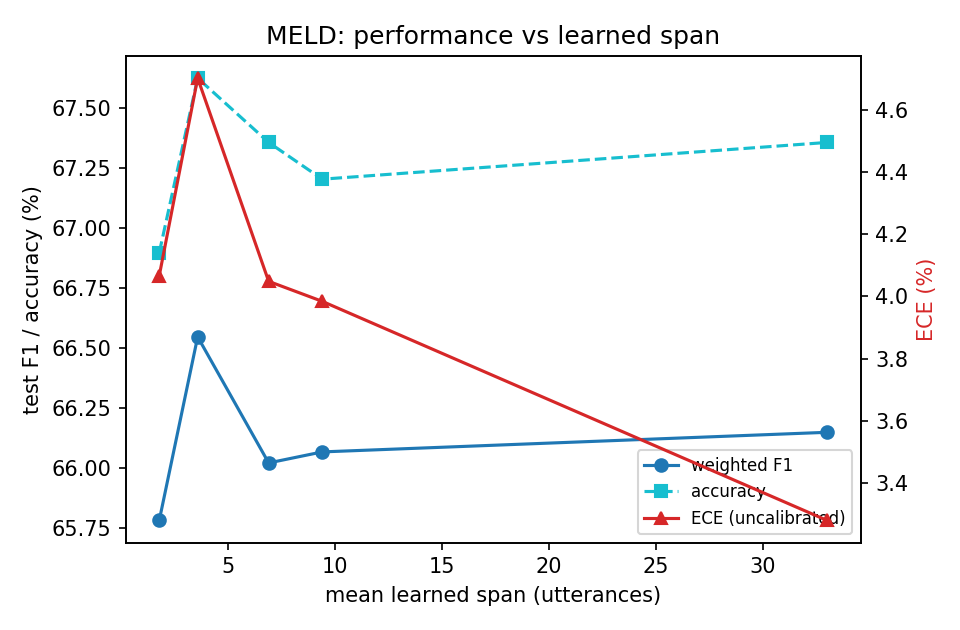

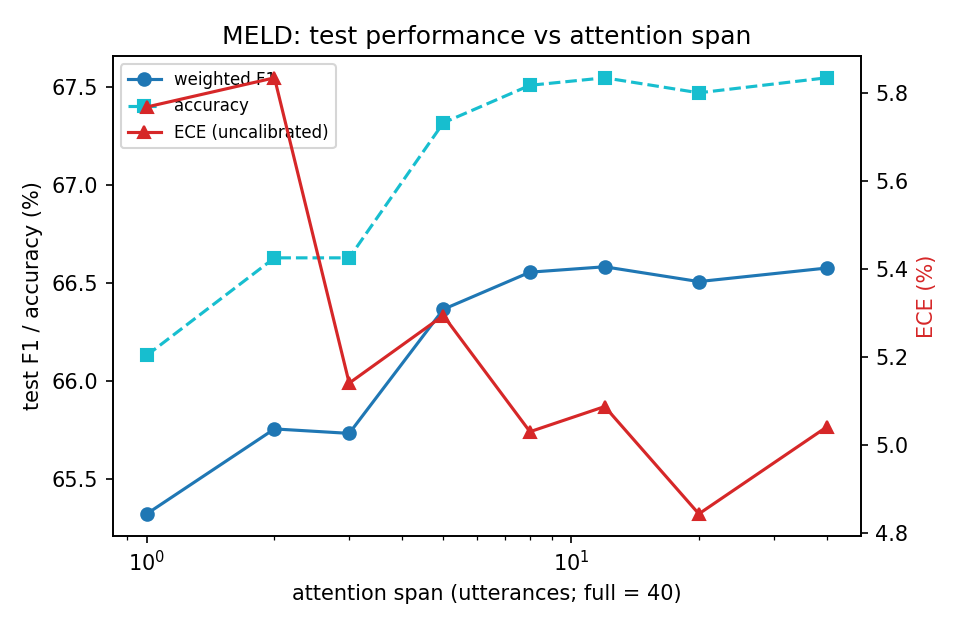


 IEMOCAP
dialogue_length_stats_IEMOCAP.json 98 bytes
learned_span_curve_IEMOCAP.csv 1156 bytes
learned_span_curve_IEMOCAP.json 1989 bytes
learned_span_curve_IEMOCAP.png 91576 bytes
span_sweep_IEMOCAP.csv 1291 bytes
span_sweep_IEMOCAP.json 2936 bytes
span_sweep_IEMOCAP.png 78659 bytes


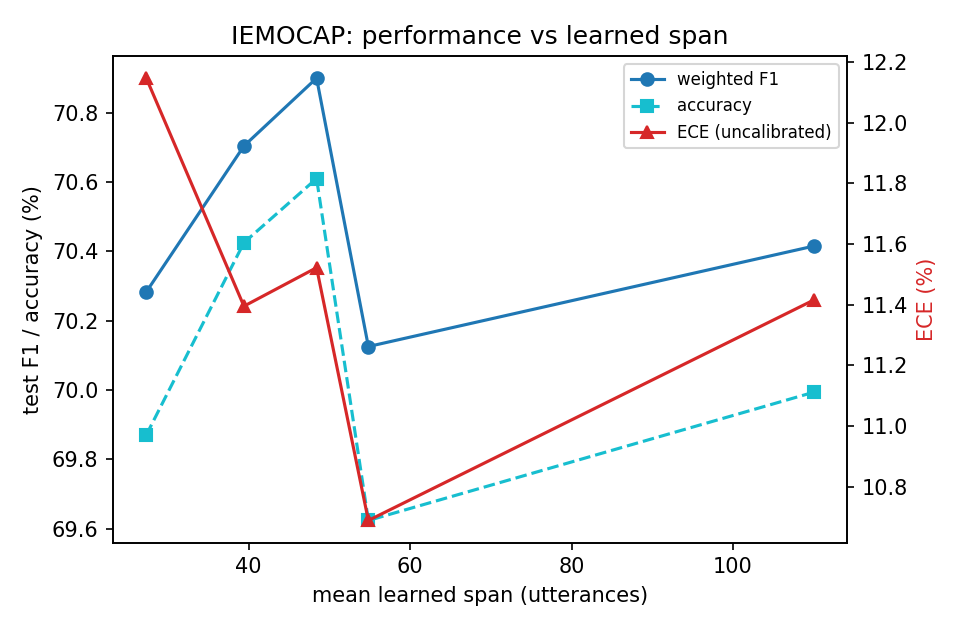

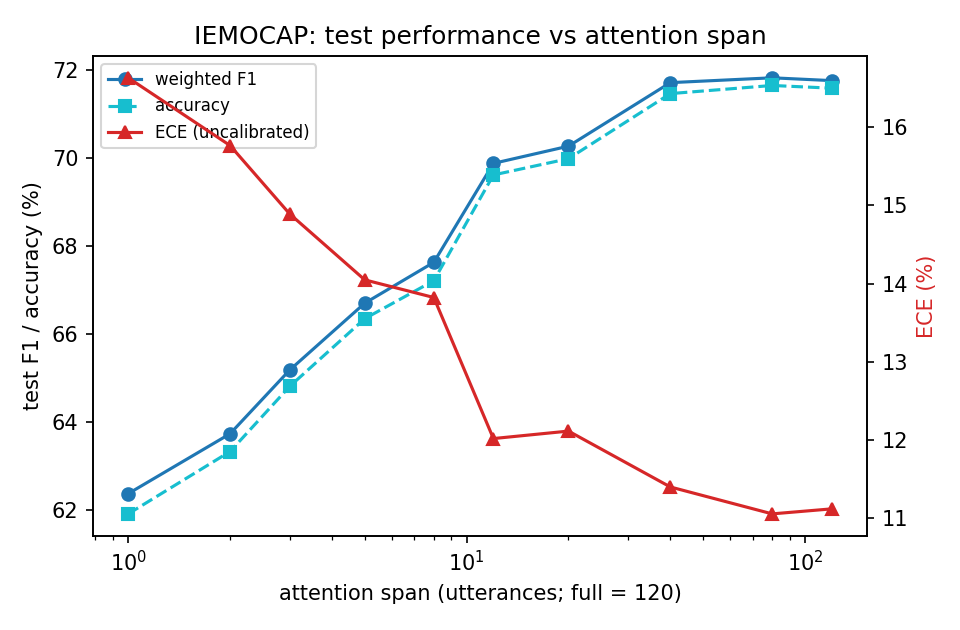

In [21]:
from pathlib import Path
from IPython.display import display, Image
root = Path("/kaggle/working/ECERC_complete")
for ds in ["MELD", "IEMOCAP"]:
    print("\n", ds)
    for f in sorted((root / ds / "span_out").glob("*")):
        print(f.name, f.stat().st_size, "bytes")
    for f in sorted((root / ds / "span_out").glob("*.png")):
        display(Image(filename=str(f)))

MELD: COMPLETE
IEMOCAP: COMPLETE
Saved: /kaggle/working/ECERC_complete/combined_per_seed_results.csv
Saved: /kaggle/working/ECERC_complete/combined_results_mean_std.csv


test_accuracy  test_weighted_f1  test_macro_f1  \
dataset method                                                           
IEMOCAP ALL (L1+L2+L4)         70.446            70.540         69.091   
        L1                     69.747            69.731         68.534   
        L1+L2                  69.747            69.833         68.784   
        L2                     69.275            69.492         68.535   
        L4                     70.076            70.268         69.150   
        baseline               69.973            70.181         69.074   
MELD    ALL (L1+L2+L4)         66.782            65.797         49.571   
        L1                     66.679            65.690         49.754   
        L1+L2                  66.692            65.744         49.749   
        L2                     67.050            65.867         49.220   
        L4                     66.935            65.880         49.377   
        baseline               66.833            65.719         49.569   

                        test_ece  test_nll  test_brier  
dataset method                                          
IEMOCAP ALL (L1+L2+L4)     4.728     0.738       0.409  
        L1                 3.172     0.742       0.413  
        L1+L2              2.995     0.741       0.412  
        L2                 9.398     0.797       0.432  
        L4                11.215     0.802       0.430  
        baseline          12.204     0.818       0.432  
MELD    ALL (L1+L2+L4)     5.321     0.984       0.466  
        L1                 3.539     0.979       0.466  
        L1+L2              5.586     0.993       0.469  
        L2                 5.251     0.986       0.467  
        L4                 3.724     0.971       0.463  
        baseline           3.022     0.975       0.465

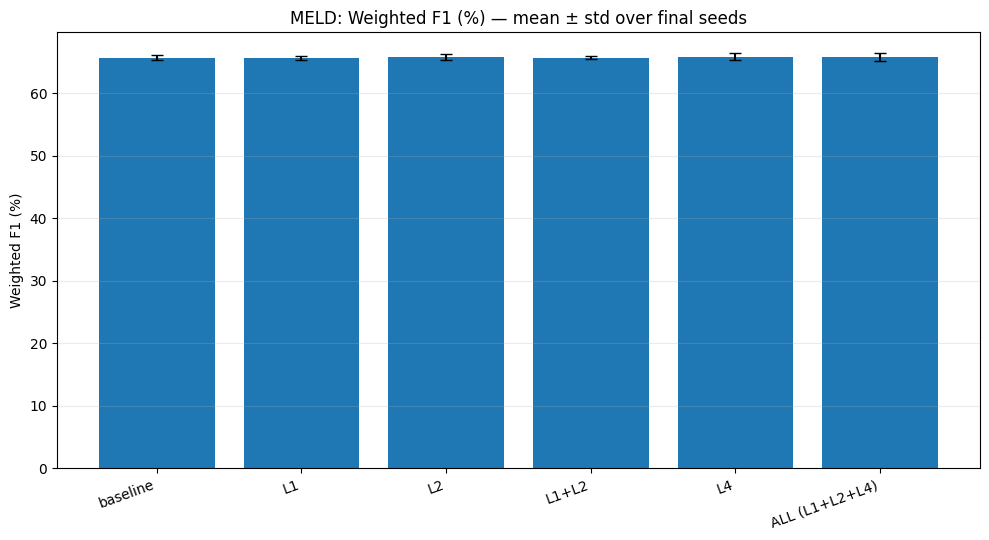

Saved: /kaggle/working/ECERC_complete/analysis_plots/MELD_weighted_f1.png


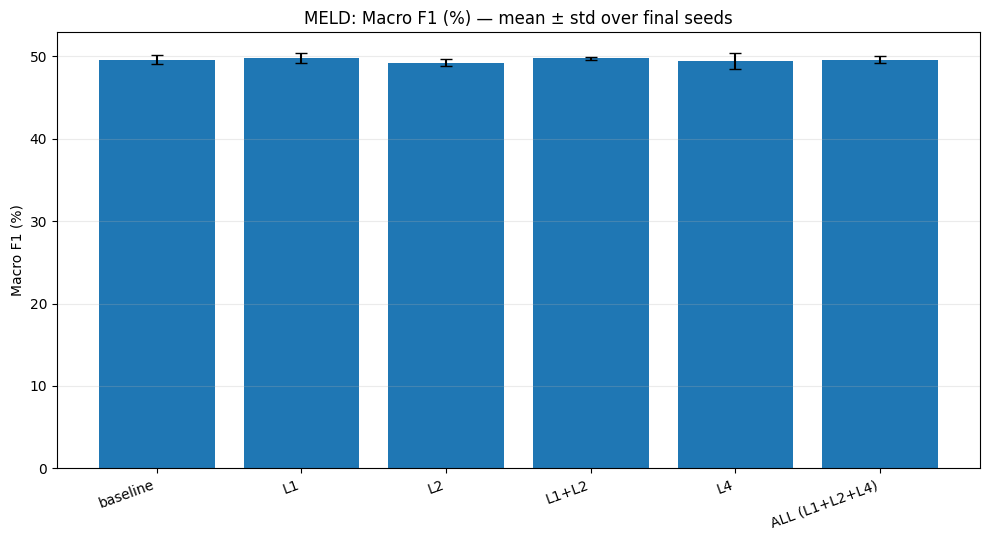

Saved: /kaggle/working/ECERC_complete/analysis_plots/MELD_macro_f1.png


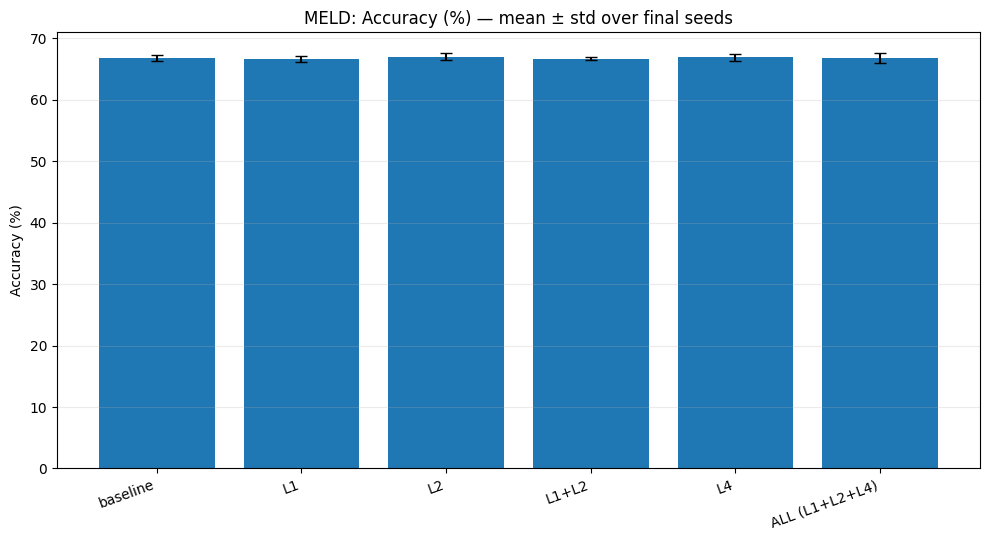

Saved: /kaggle/working/ECERC_complete/analysis_plots/MELD_accuracy.png


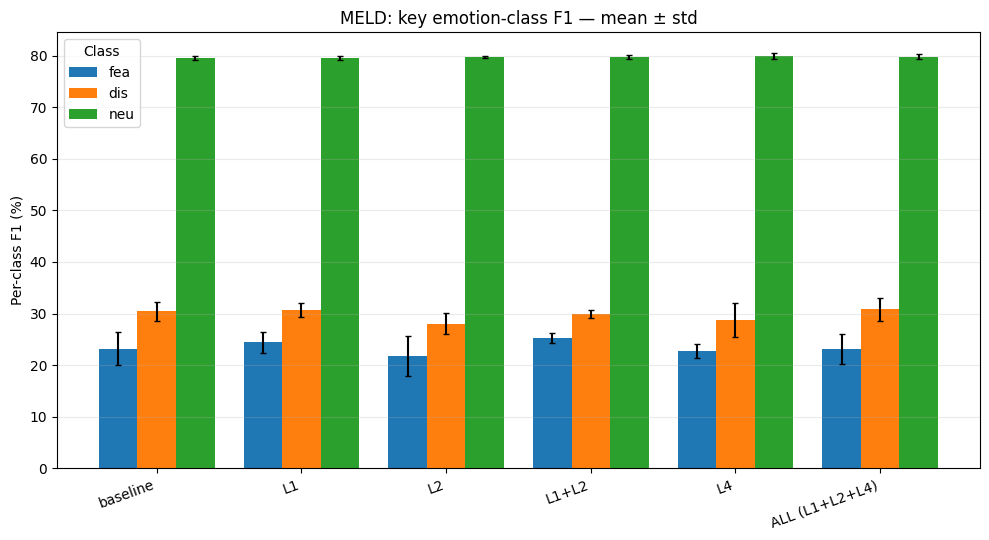

Saved: /kaggle/working/ECERC_complete/analysis_plots/MELD_key_class_f1.png


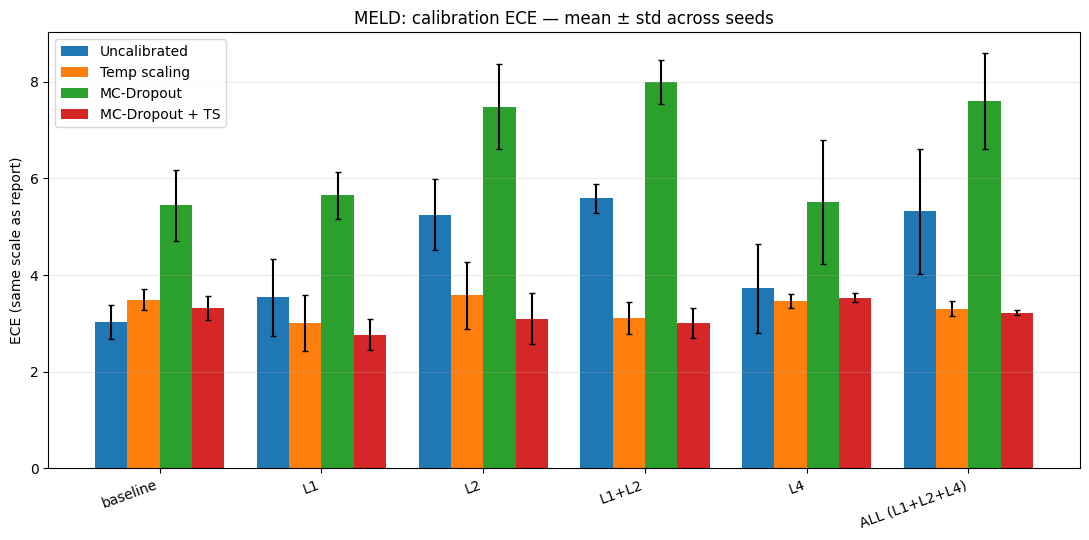

Saved: /kaggle/working/ECERC_complete/analysis_plots/MELD_calibration_ece.png


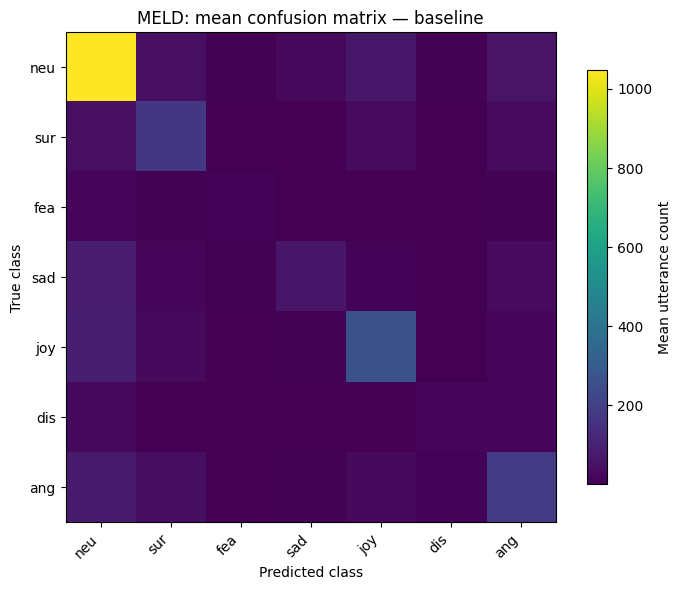

Saved: /kaggle/working/ECERC_complete/analysis_plots/MELD_confusion_baseline.png


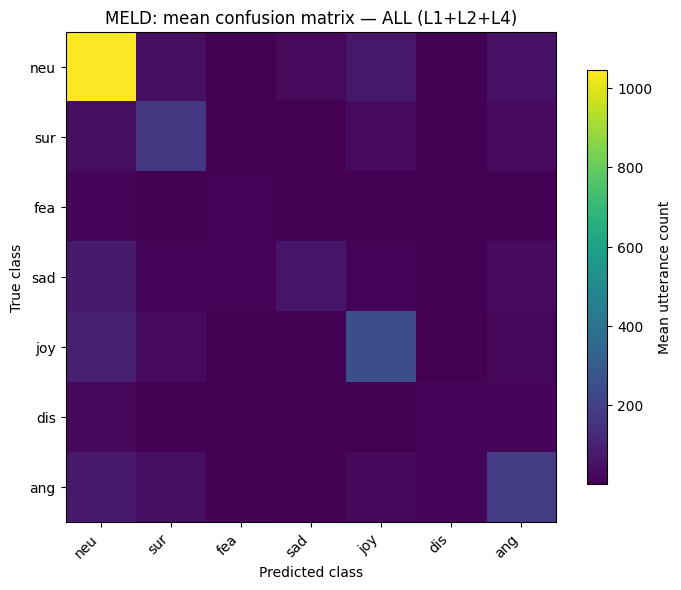

Saved: /kaggle/working/ECERC_complete/analysis_plots/MELD_confusion_ALL.png


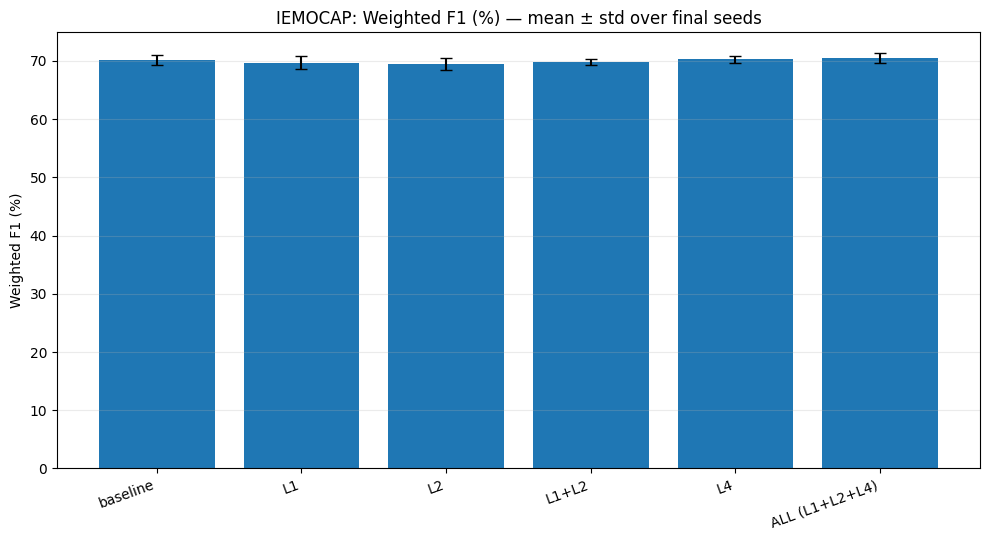

Saved: /kaggle/working/ECERC_complete/analysis_plots/IEMOCAP_weighted_f1.png


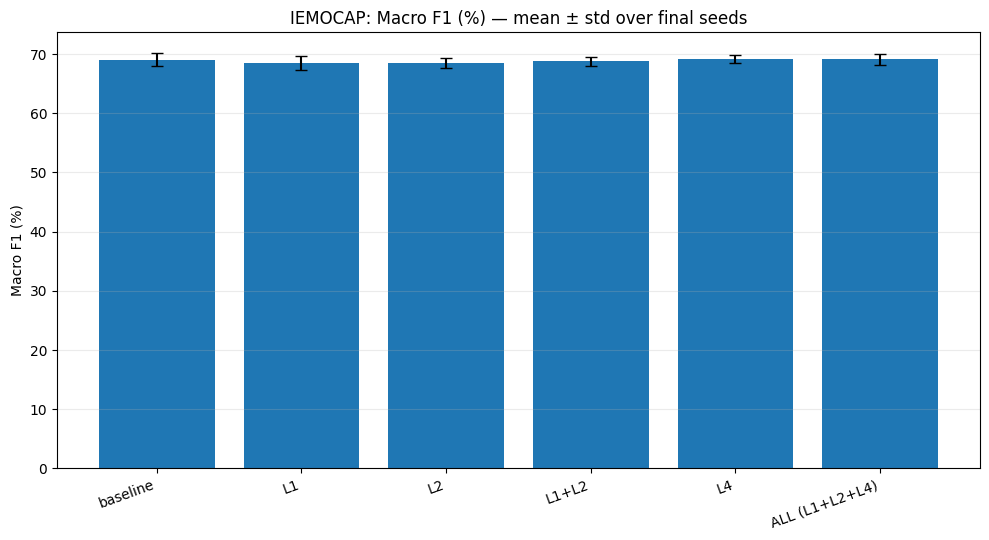

Saved: /kaggle/working/ECERC_complete/analysis_plots/IEMOCAP_macro_f1.png


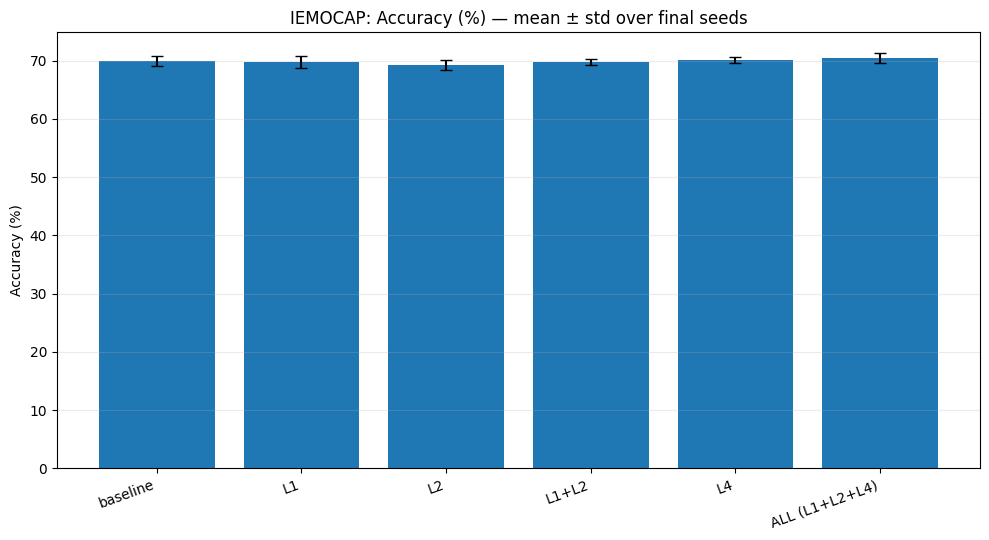

Saved: /kaggle/working/ECERC_complete/analysis_plots/IEMOCAP_accuracy.png


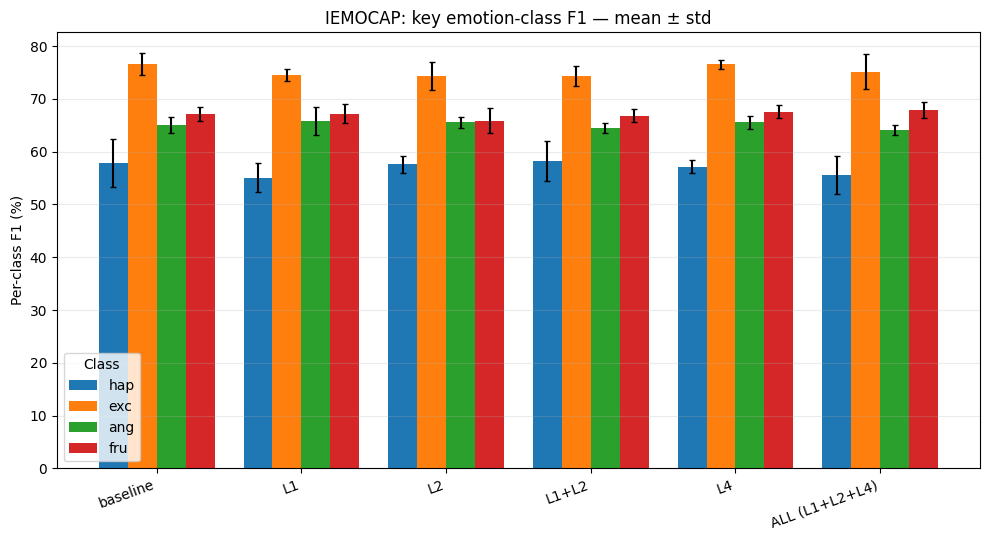

Saved: /kaggle/working/ECERC_complete/analysis_plots/IEMOCAP_key_class_f1.png


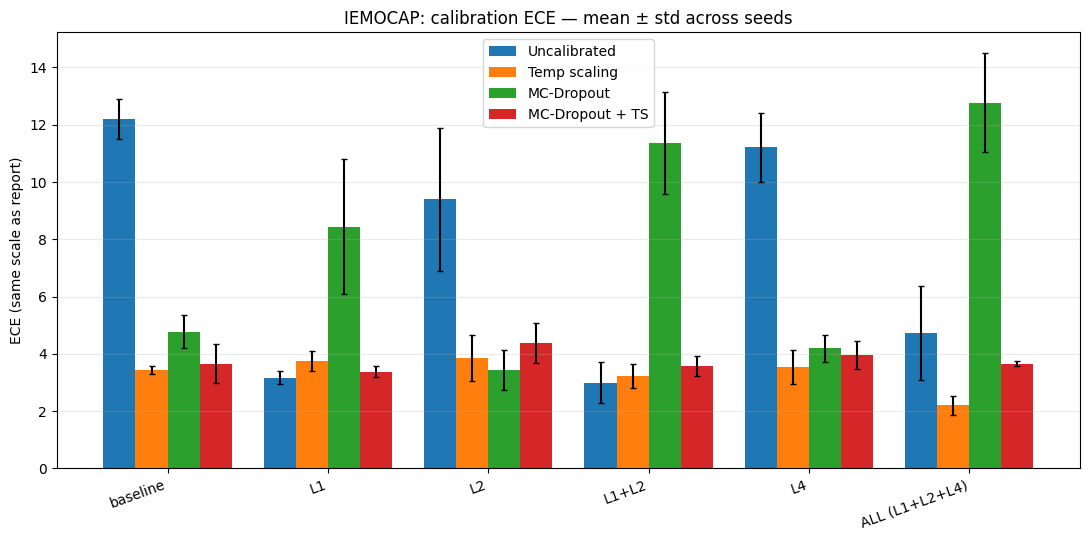

Saved: /kaggle/working/ECERC_complete/analysis_plots/IEMOCAP_calibration_ece.png


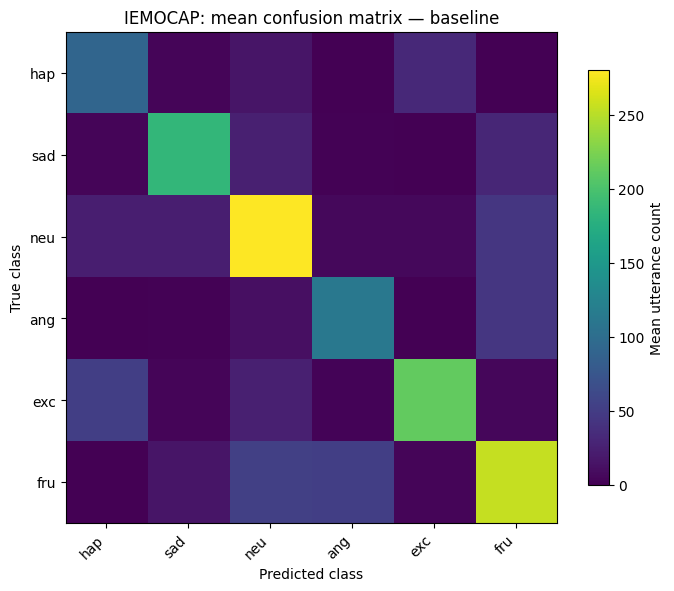

Saved: /kaggle/working/ECERC_complete/analysis_plots/IEMOCAP_confusion_baseline.png


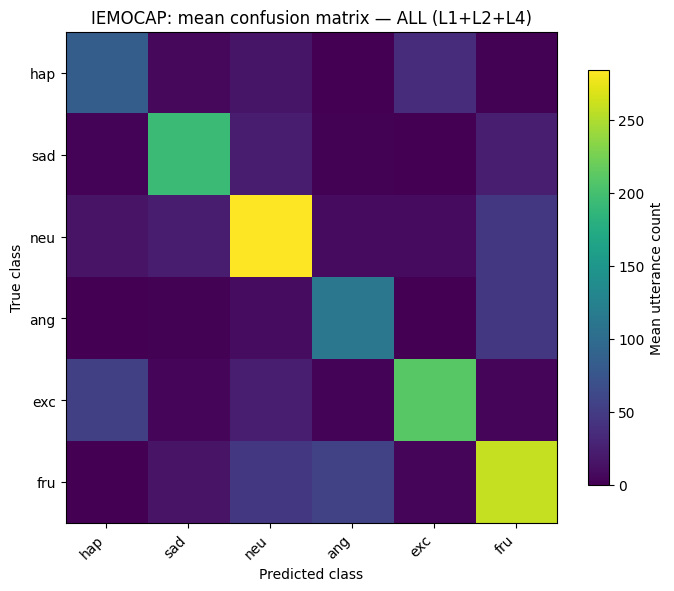

Saved: /kaggle/working/ECERC_complete/analysis_plots/IEMOCAP_confusion_ALL.png

Analysis plot directory: /kaggle/working/ECERC_complete/analysis_plots


In [22]:
from pathlib import Path
import json, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

root = Path("/kaggle/working/ECERC_complete")
plot_dir = root / "analysis_plots"
plot_dir.mkdir(exist_ok=True)
all_rows = []
results = {}

for ds in ["MELD", "IEMOCAP"]:
    out = root / "tuning_results" / ds
    status_path = out / "status.json"
    status = json.load(open(status_path)) if status_path.exists() else {"complete": False}
    print(f"{ds}: {'COMPLETE' if status.get('complete') else 'INCOMPLETE'}")
    payload_path = out / "final_results.json"
    csv_path = out / "final_results.csv"
    if not payload_path.exists() or not csv_path.exists():
        print(f"Skipping {ds}: final result files not found yet")
        continue
    payload = json.load(open(payload_path))
    results[ds] = payload["aggregate"]
    df = pd.read_csv(csv_path)
    df.insert(0, "dataset", ds)
    all_rows.append(df)

if not all_rows:
    raise FileNotFoundError("No final_results.csv files were found. Run both auto_tune.py commands first.")

per_seed = pd.concat(all_rows, ignore_index=True)
per_seed_path = root / "combined_per_seed_results.csv"
per_seed.to_csv(per_seed_path, index=False)
metric_cols = [c for c in ["test_accuracy", "test_weighted_f1", "test_macro_f1", "test_ece", "test_nll", "test_brier"] if c in per_seed.columns]
summary = per_seed.groupby(["dataset", "method"])[metric_cols].agg(["mean", "std"]).reset_index()
summary_path = root / "combined_results_mean_std.csv"
summary.to_csv(summary_path, index=False)
print("Saved:", per_seed_path)
print("Saved:", summary_path)
display(per_seed.groupby(["dataset", "method"])[metric_cols].mean().round(3))

# Classifications: weighted F1, macro F1 and accuracy, averaged across final seeds.
for ds, agg in results.items():
    methods = list(agg.keys())
    x = np.arange(len(methods))
    for metric, label in [("weighted_f1", "Weighted F1 (%)"), ("macro_f1", "Macro F1 (%)"), ("accuracy", "Accuracy (%)")]:
        means = [agg[m]["test"][metric]["mean"] for m in methods]
        stds = [agg[m]["test"][metric]["std"] for m in methods]
        fig, ax = plt.subplots(figsize=(10, 5.5))
        ax.bar(x, means, yerr=stds, capsize=4)
        ax.set_xticks(x, methods, rotation=20, ha="right")
        ax.set_ylabel(label)
        ax.set_title(f"{ds}: {label} — mean ± std over final seeds")
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        path = plot_dir / f"{ds}_{metric}.png"
        fig.savefig(path, dpi=160)
        plt.show()
        print("Saved:", path)

    # Class-level F1: MELD minority classes and Neutral; IEMOCAP confusable pairs.
    classes = list(agg["baseline"]["per_class"].keys())
    selected = [c for c in (["fea", "dis", "neu"] if ds == "MELD" else ["hap", "exc", "ang", "fru"]) if c in classes]
    if selected:
        fig, ax = plt.subplots(figsize=(10, 5.5))
        width = 0.8 / len(selected)
        for j, cls in enumerate(selected):
            vals = [agg[m]["per_class"][cls]["f1"]["mean"] for m in methods]
            errs = [agg[m]["per_class"][cls]["f1"]["std"] for m in methods]
            ax.bar(x + (j - (len(selected)-1)/2)*width, vals, width, yerr=errs, capsize=2, label=cls)
        ax.set_xticks(x, methods, rotation=20, ha="right")
        ax.set_ylabel("Per-class F1 (%)")
        ax.set_title(f"{ds}: key emotion-class F1 — mean ± std")
        ax.legend(title="Class")
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        path = plot_dir / f"{ds}_key_class_f1.png"
        fig.savefig(path, dpi=160)
        plt.show()
        print("Saved:", path)

    # Calibration ECE comparison across methods (only if calibration results exist).
    variants = ["Uncalibrated", "Temp scaling", "MC-Dropout", "MC-Dropout + TS"]
    if all("calibration" in agg[m] for m in methods):
        fig, ax = plt.subplots(figsize=(11, 5.5))
        width = 0.8 / len(variants)
        for j, v in enumerate(variants):
            vals = [agg[m]["calibration"][v]["ece"]["mean"] for m in methods]
            errs = [agg[m]["calibration"][v]["ece"]["std"] for m in methods]
            ax.bar(x + (j - (len(variants)-1)/2)*width, vals, width, yerr=errs, capsize=2, label=v)
        ax.set_xticks(x, methods, rotation=20, ha="right")
        ax.set_ylabel("ECE (same scale as report)")
        ax.set_title(f"{ds}: calibration ECE — mean ± std across seeds")
        ax.legend()
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        path = plot_dir / f"{ds}_calibration_ece.png"
        fig.savefig(path, dpi=160)
        plt.show()
        print("Saved:", path)

    # Average confusion matrix: baseline vs combined model.
    classes = list(agg["baseline"]["per_class"].keys())
    combined = "ALL (L1+L2+L4)"
    for method in ["baseline", combined]:
        if method not in agg:
            continue
        cm = np.asarray(agg[method]["confusion_matrix_mean"], dtype=float)
        fig, ax = plt.subplots(figsize=(7, 6))
        im = ax.imshow(cm, interpolation="nearest")
        ax.set_title(f"{ds}: mean confusion matrix — {method}")
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("True class")
        ax.set_xticks(np.arange(len(classes)), classes, rotation=45, ha="right")
        ax.set_yticks(np.arange(len(classes)), classes)
        fig.colorbar(im, ax=ax, shrink=0.8, label="Mean utterance count")
        fig.tight_layout()
        path = plot_dir / f"{ds}_confusion_{'ALL' if method == combined else 'baseline'}.png"
        fig.savefig(path, dpi=160)
        plt.show()
        print("Saved:", path)

print("\nAnalysis plot directory:", plot_dir)

In [23]:
from pathlib import Path
import json
root = Path("/kaggle/working/ECERC_complete")
all_complete = True
for ds in ["MELD", "IEMOCAP"]:
    out = root / "tuning_results" / ds
    ok = (out / "STATUS_COMPLETE.txt").exists()
    status = json.load(open(out / "status.json")) if (out / "status.json").exists() else {}
    ok = ok and status.get("complete", False)
    all_complete = all_complete and ok
    print(f"{ds}: {'COMPLETE' if ok else 'INCOMPLETE'}")
    print("  trained:", status.get("trained_runs"), "/ expected:", status.get("expected_runs"))
    print("  calibrations:", status.get("calibrations_produced"), "/ expected:", status.get("expected_calibrations"))
    if not ok:
        print("  missing:", status.get("missing", [])[:10])
        print("  failures:", status.get("failures", [])[:5])
print("\nBOTH DATASETS COMPLETE:", all_complete)
for ds in ["MELD", "IEMOCAP"]:
    report = root / "tuning_results" / ds / "final_report.md"
    if report.exists():
        print(f"\n===== {ds} final_report.md (first 100 lines) =====")
        print("\n".join(report.read_text().splitlines()[:100]))

MELD: COMPLETE
  trained: 18 / expected: 18
  calibrations: 18 / expected: 18
IEMOCAP: COMPLETE
  trained: 18 / expected: 18
  calibrations: 18 / expected: 18

BOTH DATASETS COMPLETE: True

===== MELD final_report.md (first 100 lines) =====
# MELD - final results (test set evaluated once per run; "±" = sample std over seeds)

> Status: **COMPLETE** - all 18 training runs and 18 calibrations required by the protocol exist.

> L2: no setting in the grid beat the baseline on the validation score "mean" (59.73 vs 59.98); the best one is used anyway.

Protocol: checkpoint = best VALIDATION weighted-F1 epoch; test set evaluated once per run after training; settings chosen on validation only (score "mean", tuning seed(s) [0]); final seeds [0, 1, 2]; calibration: temperature fitted on validation, same ECE bins / MC passes / seed for every checkpoint.

## 1. Classification (test)

| method | seeds | accuracy | weighted F1 | macro F1 | weighted P | weighted R | macro P | macro R |
|---|---|---|-

In [24]:
from pathlib import Path
import os
import shutil
from IPython.display import display, FileLink

root = Path("/kaggle/working/ECERC_complete")
bundle = Path("/kaggle/working/ECERC_final_deliverables")
shutil.rmtree(bundle, ignore_errors=True)
bundle.mkdir(parents=True)

main_files = [
    "final_report.md", "final_results.csv", "final_results.json", "summary.md",
    "status.json", "STATUS_COMPLETE.txt", "STATUS_INCOMPLETE.txt",
    "best_config.json", "grid.csv", "runs.json"
]
for ds in ["MELD", "IEMOCAP"]:
    src = root / "tuning_results" / ds
    dst = bundle / ds
    dst.mkdir(parents=True, exist_ok=True)
    for name in main_files:
        f = src / name
        if f.is_file():
            shutil.copy2(f, dst / name)
    for name in ["calib", "logs"]:
        f = src / name
        if f.is_dir():
            shutil.copytree(f, dst / name, dirs_exist_ok=True)
    span = root / ds / "span_out"
    if span.is_dir():
        shutil.copytree(span, dst / "span_out", dirs_exist_ok=True)

plots = root / "analysis_plots"
if plots.is_dir():
    shutil.copytree(plots, bundle / "analysis_plots", dirs_exist_ok=True)
for name in ["combined_per_seed_results.csv", "combined_results_mean_std.csv"]:
    f = root / name
    if f.is_file():
        shutil.copy2(f, bundle / name)

zip_path = shutil.make_archive("/kaggle/working/ECERC_final_deliverables", "zip", root_dir=bundle)
print("Created:", zip_path, "size MiB:", round(Path(zip_path).stat().st_size / (1024**2), 2))
# The clickable link appears in the cell output.
os.chdir("/kaggle/working")
display(FileLink("ECERC_final_deliverables.zip"))

Created: /kaggle/working/ECERC_final_deliverables.zip size MiB: 4.93


/kaggle/working/ECERC_final_deliverables.zip

In [27]:
%cd /kaggle/working/ECERC_complete

!python auto_tune.py MELD \
    --tune_seed 100 \
    --seeds 0 1 2 \
    --select mean \
    --ensemble

/kaggle/working/ECERC_complete
=== [1/5] baseline (authors' code), tuning seed(s) [100] ===
  >> baseline_s100  (baseline)
     validation: wF1 66.28 | macro-F1 53.47
=== [2/5] tuning each fix on its own (validation only) ===
=== grid: L1 (12 settings x 1 tuning seed(s); chosen by mean VALIDATION score "mean") ===
  >> lim1_cb_beta_0.99_focal_gamma_0.5_s100  --lim1 --cb_beta 0.99 --focal_gamma 0.5
     validation: wF1 66.17 | macro-F1 53.44
  >> lim1_cb_beta_0.99_focal_gamma_1.0_s100  --lim1 --cb_beta 0.99 --focal_gamma 1.0
     validation: wF1 66.18 | macro-F1 53.27
  >> lim1_cb_beta_0.99_focal_gamma_2.0_s100  --lim1 --cb_beta 0.99 --focal_gamma 2.0
     validation: wF1 65.90 | macro-F1 54.45
  >> lim1_cb_beta_0.995_focal_gamma_0.5_s100  --lim1 --cb_beta 0.995 --focal_gamma 0.5
     validation: wF1 65.90 | macro-F1 53.62
  >> lim1_cb_beta_0.995_focal_gamma_1.0_s100  --lim1 --cb_beta 0.995 --focal_gamma 1.0
     validation: wF1 65.89 | macro-F1 53.36
  >> lim1_cb_beta_0.995_focal_gamma

In [2]:
%cd /kaggle/working/ECERC_complete

!python auto_tune.py IEMOCAP \
    --tune_seed 2100 \
    --seeds 2007 2008 2009 \
    --select mean \
    --ensemble

/kaggle/working/ECERC_complete
=== [1/5] baseline (authors' code), tuning seed(s) [2100] ===
  >> baseline_s2100  (baseline)
     validation: wF1 74.79 | macro-F1 71.34
=== [2/5] tuning each fix on its own (validation only) ===
=== grid: L1 (6 settings x 1 tuning seed(s); chosen by mean VALIDATION score "mean") ===
  >> lim1_cb_beta_0.999_focal_gamma_0.0_s2100  --lim1 --cb_beta 0.999 --focal_gamma 0.0
     validation: wF1 74.97 | macro-F1 71.40
  >> lim1_cb_beta_0.999_focal_gamma_1.0_s2100  --lim1 --cb_beta 0.999 --focal_gamma 1.0
     validation: wF1 75.58 | macro-F1 71.68
  >> lim1_cb_beta_0.999_focal_gamma_2.0_s2100  --lim1 --cb_beta 0.999 --focal_gamma 2.0
     validation: wF1 75.07 | macro-F1 71.21
  >> lim1_cb_beta_0.9999_focal_gamma_0.0_s2100  --lim1 --cb_beta 0.9999 --focal_gamma 0.0
     validation: wF1 74.65 | macro-F1 71.27
  >> lim1_cb_beta_0.9999_focal_gamma_1.0_s2100  --lim1 --cb_beta 0.9999 --focal_gamma 1.0
     validation: wF1 74.63 | macro-F1 70.96
  >> lim1_cb_beta_0

In [4]:
from pathlib import Path
import json
import pandas as pd

root = Path("/kaggle/working/ECERC_complete")

for ds in ["MELD", "IEMOCAP"]:
    out = root / "tuning_results" / ds

    print("\n" + "=" * 60)
    print(ds)

    status = json.loads((out / "status.json").read_text())
    print("Complete:", status["complete"])

    print("\nSelected configuration:")
    print((out / "best_config.json").read_text())

    print("\nValidation hyperparameter search:")
    grid = pd.read_csv(out / "grid.csv")
    print(grid.sort_values("score", ascending=False).to_string(index=False))

    print("\nFinal test results:")
    report = (out / "final_report.md").read_text()
    print(report[:3500])


MELD
Complete: True

Selected configuration:
{
  "dataset": "MELD",
  "tune_seeds": [
    100
  ],
  "select": "mean",
  "L1_ARGS": "--cb_beta 0.999 --focal_gamma 0.5",
  "L2_ARGS": "--ls_eps 0.1 --ls_neighbor_mass 0.5",
  "L4_ARGS": "--span_penalty 0.005"
}

Validation hyperparameter search:
limitation         setting  tune_seeds  valid_wf1  valid_macro     score  score_std  mean_span
        L1  L1_b0.999_g0.5           1  66.503604    54.282196 60.392900        0.0        NaN
        L2    L2_e0.1_m0.5           1  66.154520    54.439079 60.296799        0.0        NaN
        L1   L1_b0.99_g2.0           1  65.901153    54.448241 60.174697        0.0        NaN
        L2    L2_e0.1_m0.9           1  66.005457    54.144728 60.075093        0.0        NaN
        L1  L1_b0.999_g1.0           1  66.227683    53.751822 59.989753        0.0        NaN
        L4       L4_p0.005           1  66.134388    53.640879 59.887633        0.0   6.623149
        L1 L1_b0.9995_g0.5           1  

In [5]:
from pathlib import Path
import shutil

ROOT = Path("/kaggle/working/ECERC_complete")

assert (ROOT / "auto_tune.py").exists(), "Project root not found"

BACKUP = Path("/kaggle/working/ECERC_backup_before_L1L4")
BACKUP.mkdir(exist_ok=True)

def patch_file(path, replacements):
    text = path.read_text()

    for old, new, label in replacements:
        if new in text:
            print("Already patched:", label)
            continue

        count = text.count(old)
        if count != 1:
            raise RuntimeError(
                f"{label}: expected one match, found {count}"
            )

        text = text.replace(old, new, 1)
        print("Patched:", label)

    path.write_text(text)


auto = ROOT / "auto_tune.py"
smoke = ROOT / "tests" / "smoke_test.py"

shutil.copy2(auto, BACKUP / "auto_tune.py")
shutil.copy2(smoke, BACKUP / "smoke_test.py")

patch_file(auto, [
    (
        "METHOD_ORDER = ['baseline', 'L1', 'L2', 'L1+L2', 'L4', 'ALL (L1+L2+L4)']",
        "METHOD_ORDER = ['baseline', 'L1', 'L2', 'L1+L2', 'L4', 'L1+L4', 'ALL (L1+L2+L4)']",
        "Method order"
    ),
    (
        "    ap.add_argument('--ensemble', action='store_true', help='OPTIONAL extra: also ensemble the seeds of baseline and ALL (ensemble_eval.py)')",
        "    ap.add_argument('--ensemble', action='store_true', help='OPTIONAL extra: also ensemble the seeds of baseline and ALL (ensemble_eval.py)')\n    ap.add_argument('--out_root', type=str, default=None, help='Optional output root; dataset folder is appended')",
        "Separate experiment output directory"
    ),
    (
        "    R = Runner(ds, args)",
        "    R = Runner(ds, args, out_root=args.out_root)",
        "Output directory support"
    ),
    (
        "    method_flags = {'baseline': [], 'L1': F1, 'L2': F2, 'L1+L2': F1 + F2, 'L4': F4, 'ALL (L1+L2+L4)': F1 + F2 + F4}",
        "    method_flags = {'baseline': [], 'L1': F1, 'L2': F2, 'L1+L2': F1 + F2, 'L4': F4, 'L1+L4': F1 + F4, 'ALL (L1+L2+L4)': F1 + F2 + F4}",
        "Add L1+L4"
    )
])

patch_file(smoke, [
    (
        "['baseline', 'L1', 'L2', 'L1+L2', 'L4', 'ALL (L1+L2+L4)']",
        "['baseline', 'L1', 'L2', 'L1+L2', 'L4', 'L1+L4', 'ALL (L1+L2+L4)']",
        "Smoke-test method list"
    ),
    (
        "        self.assertIn('span', agg['L4']); self.assertIn('span', agg['ALL (L1+L2+L4)']); self.assertNotIn('span', agg['baseline'])",
        "        self.assertIn('span', agg['L4']); self.assertIn('span', agg['L1+L4']); self.assertIn('span', agg['ALL (L1+L2+L4)']); self.assertNotIn('span', agg['baseline'])",
        "Smoke-test span check"
    ),
    (
        "(12, 12, 12, 12)",
        "(14, 14, 14, 14)",
        "Smoke-test expected runs"
    ),
    (
        "self.assertEqual(len(rows), 12)",
        "self.assertEqual(len(rows), 14)",
        "Smoke-test CSV row count"
    )
])

print("\nL1+L4 patch completed.")

Patched: Method order
Patched: Separate experiment output directory
Patched: Output directory support
Patched: Add L1+L4
Patched: Smoke-test method list
Patched: Smoke-test span check
Patched: Smoke-test expected runs
Patched: Smoke-test CSV row count

L1+L4 patch completed.


In [6]:
%cd /kaggle/working/ECERC_complete

!python -m py_compile auto_tune.py MELD/train.py IEMOCAP/train.py tests/smoke_test.py

!python tests/run_tests.py

/kaggle/working/ECERC_complete
test_authors_gamma_constant_in_train_py_matches_official_default (__main__.TestLoss.test_authors_gamma_constant_in_train_py_matches_official_default) ... /kaggle/working/ECERC_complete/tests/run_tests.py:88: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/ECERC_complete/tests/reference/official_MELD_loss.py' mode='r' encoding='utf-8'>
  g_official = re.search(r'class Loss.*?def __init__\(self, gamma=([\d.]+)', open(os.path.join(REF, 'official_%s_loss.py' % ds)).read(), re.S).group(1)
/kaggle/working/ECERC_complete/tests/run_tests.py:88: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/ECERC_complete/tests/reference/official_IEMOCAP_loss.py' mode='r' encoding='utf-8'>
  g_official = re.search(r'class Loss.*?def __init__\(self, gamma=([\d.]+)', open(os.path.join(REF, 'official_%s_loss.py' % ds)).read(), re.S).group(1)
ok
test_authors_loss_class_is_byte_identical_to_official (__main__.TestLoss.test_authors_loss_

In [7]:
from pathlib import Path
import shutil

ROOT = Path("/kaggle/working/ECERC_complete")
ARCHIVE = Path("/kaggle/working/ECERC_previous_mean_results")

for ds in ["MELD", "IEMOCAP"]:

    src = ROOT / "tuning_results" / ds
    dst = ARCHIVE / ds
    dst.mkdir(parents=True, exist_ok=True)

    for filename in [
        "final_report.md",
        "final_results.csv",
        "final_results.json",
        "summary.md",
        "grid.csv",
        "best_config.json",
        "status.json",
        "runs.json",
        "STATUS_COMPLETE.txt"
    ]:
        f = src / filename
        if f.exists():
            shutil.copy2(f, dst / filename)

    # Do not reuse calibration results if their training checkpoint
    # is missing and must be recreated.
    ckpt_dir = src / "ckpts"
    calib_dir = src / "calib"

    for result_file in ckpt_dir.glob("*_results.json"):
        stem = result_file.name[:-len("_results.json")]
        checkpoint = ckpt_dir / (stem + ".pkl")

        if not checkpoint.exists():
            old_calibration = calib_dir / stem
            if old_calibration.exists():
                shutil.rmtree(old_calibration)

    print(ds, "previous reports backed up")

print("Previous results preserved.")

MELD previous reports backed up
IEMOCAP previous reports backed up
Previous results preserved.


In [8]:
%cd /kaggle/working/ECERC_complete

!python auto_tune.py MELD \
    --final_only \
    --resume \
    --seeds 0 1 2 \
    --ensemble

/kaggle/working/ECERC_complete
=== final-only: L1 ['--lim1', '--cb_beta', '0.999', '--focal_gamma', '0.5'] | L2 ['--lim2', '--ls_eps', '0.1', '--ls_neighbor_mass', '0.5'] | L4 ['--lim4', '--span_penalty', '0.005'] ===
=== [3/5] final comparison: 7 methods x seeds [0, 1, 2] (same protocol for all) ===
     validation: wF1 65.81 | macro-F1 54.16
     validation: wF1 66.08 | macro-F1 53.55
     validation: wF1 66.15 | macro-F1 54.86
     validation: wF1 66.07 | macro-F1 53.41
     validation: wF1 65.66 | macro-F1 53.15 | mean span 6.9
  >> lim1_cb_beta_0.999_focal_gamma_0.5_lim4_span_penalty_0.005_s0  --lim1 --cb_beta 0.999 --focal_gamma 0.5 --lim4 --span_penalty 0.005
     validation: wF1 66.09 | macro-F1 53.31 | mean span 6.6
     validation: wF1 66.14 | macro-F1 53.46 | mean span 5.6
  >> baseline_s1  (baseline)
     validation: wF1 66.03 | macro-F1 54.08
  >> lim1_cb_beta_0.999_focal_gamma_0.5_s1  --lim1 --cb_beta 0.999 --focal_gamma 0.5
     validation: wF1 66.64 | macro-F1 54.61
  >

In [11]:
%cd /kaggle/working/ECERC_complete

!python auto_tune.py IEMOCAP \
    --final_only \
    --resume \
    --seeds 2007 2008 2009 \
    --ensemble

/kaggle/working/ECERC_complete
=== final-only: L1 ['--lim1', '--cb_beta', '0.999', '--focal_gamma', '1.0'] | L2 ['--lim2', '--ls_eps', '0.02', '--ls_neighbor_mass', '0.9'] | L4 ['--lim4', '--span_penalty', '0.1'] ===
=== [3/5] final comparison: 7 methods x seeds [2007, 2008, 2009] (same protocol for all) ===
     validation: wF1 74.79 | macro-F1 70.95
     validation: wF1 75.02 | macro-F1 70.61
     validation: wF1 74.77 | macro-F1 70.95
     validation: wF1 75.03 | macro-F1 70.64
     validation: wF1 75.24 | macro-F1 71.39 | mean span 27.3
     validation: wF1 74.72 | macro-F1 71.11 | mean span 8.7
     validation: wF1 75.27 | macro-F1 71.38 | mean span 8.7
  >> baseline_s2008  (baseline)
     validation: wF1 74.04 | macro-F1 70.73
  >> lim1_cb_beta_0.999_focal_gamma_1.0_s2008  --lim1 --cb_beta 0.999 --focal_gamma 1.0
     validation: wF1 74.76 | macro-F1 71.67
  >> lim2_ls_eps_0.02_ls_neighbor_mass_0.9_s2008  --lim2 --ls_eps 0.02 --ls_neighbor_mass 0.9
     validation: wF1 74.04 | ma

In [12]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/kaggle/working/ECERC_complete")

for ds in ["MELD", "IEMOCAP"]:

    folder = ROOT / "tuning_results" / ds

    status = json.loads((folder / "status.json").read_text())

    print("\n", "=" * 65)
    print(ds)
    print("Complete:", status["complete"])
    print("Training runs:", status["trained_runs"])
    print("Calibrations:", status["calibrations_produced"])

    df = pd.read_csv(folder / "final_results.csv")

    print(
        df.groupby("method")[
            ["test_weighted_f1", "test_macro_f1", "test_accuracy"]
        ].agg(["mean", "std"]).round(3)
    )


MELD
Complete: True
Training runs: 21
Calibrations: 21
               test_weighted_f1        test_macro_f1        test_accuracy  \
                           mean    std          mean    std          mean   
method                                                                      
ALL (L1+L2+L4)           65.639  0.591        49.593  0.872        65.530   
L1                       65.694  0.449        49.796  0.909        65.670   
L1+L2                    65.743  0.185        49.874  0.666        65.760   
L1+L4                    65.995  0.569        50.194  0.725        66.028   
L2                       65.823  0.484        49.437  0.604        67.024   
L4                       65.661  0.361        48.898  0.830        66.884   
baseline                 65.719  0.382        49.569  0.541        66.833   

                       
                  std  
method                 
ALL (L1+L2+L4)  0.657  
L1              0.304  
L1+L2           0.059  
L1+L4           0.655  
L2   

In [13]:
%cd /kaggle/working/ECERC_complete

!python auto_tune.py MELD \
    --tune_seed 101 \
    --seeds 0 1 2 \
    --select macro \
    --ensemble \
    --out_root /kaggle/working/ECERC_macro_experiments


/kaggle/working/ECERC_complete
=== [1/5] baseline (authors' code), tuning seed(s) [101] ===
  >> baseline_s101  (baseline)
     validation: wF1 66.82 | macro-F1 55.12
=== [2/5] tuning each fix on its own (validation only) ===
=== grid: L1 (12 settings x 1 tuning seed(s); chosen by mean VALIDATION score "macro") ===
  >> lim1_cb_beta_0.99_focal_gamma_0.5_s101  --lim1 --cb_beta 0.99 --focal_gamma 0.5
     validation: wF1 66.74 | macro-F1 54.25
  >> lim1_cb_beta_0.99_focal_gamma_1.0_s101  --lim1 --cb_beta 0.99 --focal_gamma 1.0
     validation: wF1 66.71 | macro-F1 54.69
  >> lim1_cb_beta_0.99_focal_gamma_2.0_s101  --lim1 --cb_beta 0.99 --focal_gamma 2.0
     validation: wF1 66.57 | macro-F1 53.71
  >> lim1_cb_beta_0.995_focal_gamma_0.5_s101  --lim1 --cb_beta 0.995 --focal_gamma 0.5
     validation: wF1 66.72 | macro-F1 54.05
  >> lim1_cb_beta_0.995_focal_gamma_1.0_s101  --lim1 --cb_beta 0.995 --focal_gamma 1.0
     validation: wF1 67.09 | macro-F1 55.06
  >> lim1_cb_beta_0.995_focal_gamm

In [1]:
%cd /kaggle/working/ECERC_complete

!python auto_tune.py IEMOCAP \
    --tune_seed 2110 \
    --seeds 2007 2008 2009 \
    --select macro \
    --ensemble \
    --out_root /kaggle/working/ECERC_macro_experiments

/kaggle/working/ECERC_complete
=== [1/5] baseline (authors' code), tuning seed(s) [2110] ===
  >> baseline_s2110  (baseline)
     validation: wF1 75.06 | macro-F1 71.21
=== [2/5] tuning each fix on its own (validation only) ===
=== grid: L1 (6 settings x 1 tuning seed(s); chosen by mean VALIDATION score "macro") ===
  >> lim1_cb_beta_0.999_focal_gamma_0.0_s2110  --lim1 --cb_beta 0.999 --focal_gamma 0.0
     validation: wF1 75.09 | macro-F1 71.20
  >> lim1_cb_beta_0.999_focal_gamma_1.0_s2110  --lim1 --cb_beta 0.999 --focal_gamma 1.0
     validation: wF1 75.37 | macro-F1 71.36
  >> lim1_cb_beta_0.999_focal_gamma_2.0_s2110  --lim1 --cb_beta 0.999 --focal_gamma 2.0
     validation: wF1 75.76 | macro-F1 72.04
  >> lim1_cb_beta_0.9999_focal_gamma_0.0_s2110  --lim1 --cb_beta 0.9999 --focal_gamma 0.0
     validation: wF1 74.90 | macro-F1 71.48
  >> lim1_cb_beta_0.9999_focal_gamma_1.0_s2110  --lim1 --cb_beta 0.9999 --focal_gamma 1.0
     validation: wF1 75.44 | macro-F1 71.40
  >> lim1_cb_beta_

In [2]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/kaggle/working/ECERC_complete")

for ds in ["MELD", "IEMOCAP"]:

    mean_dir = ROOT / "tuning_results" / ds
    macro_dir = Path(
        "/kaggle/working/ECERC_macro_experiments"
    ) / ds

    print("\n", "=" * 70)
    print(ds)

    for name, folder in [
        ("Mean selection", mean_dir),
        ("Macro selection", macro_dir)
    ]:

        status = json.loads((folder / "status.json").read_text())

        print("\n", name)
        print("Complete:", status["complete"])

        df = pd.read_csv(folder / "final_results.csv")

        summary = (
            df.groupby("method")[
                ["test_weighted_f1", "test_macro_f1"]
            ].mean().round(3)
        )

        print(summary)


MELD

 Mean selection
Complete: True
                test_weighted_f1  test_macro_f1
method                                         
ALL (L1+L2+L4)            65.639         49.593
L1                        65.694         49.796
L1+L2                     65.743         49.874
L1+L4                     65.995         50.194
L2                        65.823         49.437
L4                        65.661         48.898
baseline                  65.719         49.569

 Macro selection
Complete: True
                test_weighted_f1  test_macro_f1
method                                         
ALL (L1+L2+L4)            66.032         49.883
L1                        66.017         50.162
L1+L2                     66.010         49.954
L1+L4                     65.743         49.752
L2                        65.848         49.311
L4                        65.640         48.873
baseline                  65.719         49.569

IEMOCAP

 Mean selection
Complete: True
                test_wei

In [3]:
from pathlib import Path
import shutil

ROOT = Path("/kaggle/working/ECERC_complete")

BACKUP = Path("/kaggle/working/ECERC_warmstart_backup")
BACKUP.mkdir(exist_ok=True)

warm_code = '''    if args.init_checkpoint:
        init_state = torch.load(
            args.init_checkpoint,
            map_location='cpu'
        )

        if isinstance(init_state, dict) and 'state_dict' in init_state:
            init_state = init_state['state_dict']

        incompatible = model.load_state_dict(
            init_state,
            strict=False
        )

        missing = list(incompatible.missing_keys)
        unexpected = list(incompatible.unexpected_keys)

        bad_missing = [
            k for k in missing
            if not k.startswith('span_modules.')
        ]

        if unexpected or bad_missing:
            raise RuntimeError(
                'Checkpoint architecture mismatch. '
                'Missing: {} Unexpected: {}'.format(
                    bad_missing, unexpected
                )
            )

        if not args.lim4 and missing:
            raise RuntimeError(
                'Unexpected missing parameters: {}'.format(missing)
            )

        print(
            'Pretrained initialization successful:',
            args.init_checkpoint
        )
        print('Loaded tensors:', len(init_state))
        print('New span tensors:', len(missing))

'''

for ds in ["MELD", "IEMOCAP"]:

    p = ROOT / ds / "train.py"
    text = p.read_text()

    if "--init_checkpoint" in text:
        print(ds, "already patched")
        continue

    shutil.copy2(p, BACKUP / f"{ds}_train.py")

    seed_lines = [
        line for line in text.splitlines()
        if "parser.add_argument('--seed'" in line
    ]

    assert len(seed_lines) == 1, f"{ds}: seed argument not found"

    seed_line = seed_lines[0]

    text = text.replace(
        seed_line,
        seed_line + "\n    parser.add_argument('--init_checkpoint', type=str, default=None, help='Optional pretrained ECERC checkpoint')",
        1
    )

    marker = "    if cuda_flag:\n        print('Running on GPU')"

    assert text.count(marker) == 1

    text = text.replace(
        marker,
        warm_code + marker,
        1
    )

    p.write_text(text)

    print(ds, "pretrained initialization added")

print("Both training scripts patched.")

MELD pretrained initialization added
IEMOCAP pretrained initialization added
Both training scripts patched.


In [4]:
%cd /kaggle/working/ECERC_complete

!python -m py_compile MELD/train.py IEMOCAP/train.py

/kaggle/working/ECERC_complete


In [5]:
%cd /kaggle/working/ECERC_complete/MELD

!python train.py \
    --epochs 1 \
    --seed 999 \
    --init_checkpoint ECERC_MODEL.pkl \
    --save_model_path /kaggle/working/warmstart_test_MELD.pkl

/kaggle/working/ECERC_complete/MELD
Pretrained initialization successful: ECERC_MODEL.pkl
Loaded tensors: 93
New span tensors: 0
Running on GPU
The model have 5810187 paramerters in total
Running on the multi features........
Using the authors' original loss
epoch: 0, train_loss: 0.5281, train_fscore: 75.64, valid_loss: 0.7724, valid_acc: 66.82, valid_fscore: 65.38, time: 1.82 sec
Final Test performance (test set evaluated ONCE, with the best-validation checkpoint)...
Eval-metric: F1, Epoch: 0, best_eval_fscore: 65.38, Accuracy: 67.7, F1-Score: 66.4

Per-class test report at best-validation-F1 epoch (0):
              precision    recall  f1-score   support

         neu     0.7585    0.8479    0.8008      1256
         sur     0.5596    0.6014    0.5798       281
         fea     0.3214    0.1800    0.2308        50
         sad     0.6058    0.3029    0.4038       208
         joy     0.6465    0.6642    0.6552       402
         dis     0.4250    0.2500    0.3148        68
         

In [6]:
%cd /kaggle/working/ECERC_complete/IEMOCAP

!python train.py \
    --epochs 1 \
    --seed 999 \
    --init_checkpoint ECERC_MODEL.pkl \
    --save_model_path /kaggle/working/warmstart_test_IEMOCAP.pkl

/kaggle/working/ECERC_complete/IEMOCAP
Pretrained initialization successful: ECERC_MODEL.pkl
Loaded tensors: 93
New span tensors: 0
Running on GPU
The model have 5975310 paramerters in total
Running on the multi features........
Using the authors' original loss
epoch: 0, train_loss: 2.6765, train_fscore: 81.56, valid_loss: 5.1802, valid_acc: 69.88, valid_fscore: 71.35, time: 0.85 sec
Final Test performance (test set evaluated ONCE, with the best-validation checkpoint)...
Eval-metric: F1, Epoch: 0, best_eval_fscore: 71.35, Accuracy: 65.99, F1-Score: 66.37

Per-class test report at best-validation-F1 epoch (0):
              precision    recall  f1-score   support

         hap     0.3889    0.8750    0.5385       144
         sad     0.8302    0.7184    0.7702       245
         neu     0.7143    0.6771    0.6952       384
         ang     0.6327    0.7294    0.6776       170
         exc     0.9197    0.4214    0.5780       299
         fru     0.6641    0.6798    0.6719       381

   

In [10]:
%cd /kaggle/working/ECERC_complete

!python auto_tune.py MELD \
    --tune_seed 120 \
    --seeds 0 1 2 \
    --select mean \
    --ensemble \
    --extra "--init_checkpoint /kaggle/working/ECERC_complete/MELD/ECERC_MODEL.pkl" \
    --out_root /kaggle/working/ECERC_pretrained_experiments

/kaggle/working/ECERC_complete
=== [1/5] baseline (authors' code), tuning seed(s) [120] ===
  >> baseline_s120  (baseline)
     validation: wF1 66.27 | macro-F1 54.53
=== [2/5] tuning each fix on its own (validation only) ===
=== grid: L1 (12 settings x 1 tuning seed(s); chosen by mean VALIDATION score "mean") ===
  >> lim1_cb_beta_0.99_focal_gamma_0.5_s120  --lim1 --cb_beta 0.99 --focal_gamma 0.5
     validation: wF1 66.23 | macro-F1 54.74
  >> lim1_cb_beta_0.99_focal_gamma_1.0_s120  --lim1 --cb_beta 0.99 --focal_gamma 1.0
     validation: wF1 66.28 | macro-F1 54.49
  >> lim1_cb_beta_0.99_focal_gamma_2.0_s120  --lim1 --cb_beta 0.99 --focal_gamma 2.0
     validation: wF1 66.36 | macro-F1 54.91
  >> lim1_cb_beta_0.995_focal_gamma_0.5_s120  --lim1 --cb_beta 0.995 --focal_gamma 0.5
     validation: wF1 66.27 | macro-F1 54.62
  >> lim1_cb_beta_0.995_focal_gamma_1.0_s120  --lim1 --cb_beta 0.995 --focal_gamma 1.0
     validation: wF1 66.53 | macro-F1 55.15
  >> lim1_cb_beta_0.995_focal_gamma

In [11]:
%cd /kaggle/working/ECERC_complete

!python auto_tune.py IEMOCAP \
    --tune_seed 2120 \
    --seeds 2007 2008 2009 \
    --select mean \
    --ensemble \
    --extra "--init_checkpoint /kaggle/working/ECERC_complete/IEMOCAP/ECERC_MODEL.pkl" \
    --out_root /kaggle/working/ECERC_pretrained_experiments

/kaggle/working/ECERC_complete
=== [1/5] baseline (authors' code), tuning seed(s) [2120] ===
  >> baseline_s2120  (baseline)
     validation: wF1 74.75 | macro-F1 70.61
=== [2/5] tuning each fix on its own (validation only) ===
=== grid: L1 (6 settings x 1 tuning seed(s); chosen by mean VALIDATION score "mean") ===
  >> lim1_cb_beta_0.999_focal_gamma_0.0_s2120  --lim1 --cb_beta 0.999 --focal_gamma 0.0
     validation: wF1 74.86 | macro-F1 70.68
  >> lim1_cb_beta_0.999_focal_gamma_1.0_s2120  --lim1 --cb_beta 0.999 --focal_gamma 1.0
     validation: wF1 75.57 | macro-F1 71.23
  >> lim1_cb_beta_0.999_focal_gamma_2.0_s2120  --lim1 --cb_beta 0.999 --focal_gamma 2.0
     validation: wF1 74.94 | macro-F1 70.80
  >> lim1_cb_beta_0.9999_focal_gamma_0.0_s2120  --lim1 --cb_beta 0.9999 --focal_gamma 0.0
     validation: wF1 74.62 | macro-F1 70.60
  >> lim1_cb_beta_0.9999_focal_gamma_1.0_s2120  --lim1 --cb_beta 0.9999 --focal_gamma 1.0
     validation: wF1 74.92 | macro-F1 70.53
  >> lim1_cb_beta_0

In [13]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/kaggle/working")

experiments = {
    "Original mean": ROOT / "ECERC_complete" / "tuning_results",
    "L1+L4 and mean": ROOT / "ECERC_complete" / "tuning_results",
    "Macro selection": ROOT / "ECERC_macro_experiments",
    "Pretrained initialization": ROOT / "ECERC_pretrained_experiments"
}

for ds in ["MELD", "IEMOCAP"]:

    print("\n", "=" * 80)
    print(ds)

    for experiment, base in experiments.items():

        folder = base / ds

        if not (folder / "final_results.csv").exists():
            continue

        status = json.loads(
            (folder / "status.json").read_text()
        )

        if not status["complete"]:
            print(experiment, "- INCOMPLETE")
            continue

        df = pd.read_csv(folder / "final_results.csv")

        summary = (
            df.groupby("method")[
                ["test_weighted_f1", "test_macro_f1"]
            ].mean()
        )

        print("\n", experiment)
        print(summary.round(3))


MELD

 Original mean
                test_weighted_f1  test_macro_f1
method                                         
ALL (L1+L2+L4)            65.639         49.593
L1                        65.694         49.796
L1+L2                     65.743         49.874
L1+L4                     65.995         50.194
L2                        65.823         49.437
L4                        65.661         48.898
baseline                  65.719         49.569

 L1+L4 and mean
                test_weighted_f1  test_macro_f1
method                                         
ALL (L1+L2+L4)            65.639         49.593
L1                        65.694         49.796
L1+L2                     65.743         49.874
L1+L4                     65.995         50.194
L2                        65.823         49.437
L4                        65.661         48.898
baseline                  65.719         49.569

 Macro selection
                test_weighted_f1  test_macro_f1
method                         

In [2]:
!nvidia-smi


Sun Nov  1 05:33:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!nvidia-smi

import sys, importlib.util
import torch, numpy, pandas, sklearn
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))
if not torch.cuda.is_available():
    raise RuntimeError("Enable a Kaggle GPU accelerator before training.")


Sun Nov  1 05:37:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
from pathlib import Path
import shutil, zipfile

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
PROJECT_DIR = WORK_ROOT / "ECERC_complete"
EXTRACT_DIR = WORK_ROOT / "_ecerc_archive_extract"

def valid_project_root(root: Path) -> bool:
    required = [
        root / "auto_tune.py", root / "report.py", root / "PROJECT_STATUS.md",
        root / "SOP_corrections.md", root / "MELD" / "train.py",
        root / "MELD" / "ensemble_eval.py", root / "MELD" / "calibrate.py",
    ]
    if not all(p.is_file() for p in required):
        return False
    return "--ensemble" in (root / "auto_tune.py").read_text(errors="ignore")

# Preserve an already-restored working copy (and its experiment outputs).
if valid_project_root(PROJECT_DIR):
    print("Using existing writable project:", PROJECT_DIR)
else:
    archives = []
    for z in INPUT_ROOT.rglob("*.zip"):
        try:
            with zipfile.ZipFile(z) as archive:
                names = archive.namelist()
                ok = (any(n.endswith("ECERC_complete/auto_tune.py") for n in names) and
                      any(n.endswith("ECERC_complete/PROJECT_STATUS.md") for n in names) and
                      any(n.endswith("ECERC_complete/MELD/ensemble_eval.py") for n in names))
                if ok:
                    archives.append(z)
        except (zipfile.BadZipFile, OSError):
            pass
    if not archives:
        raise FileNotFoundError(
            "No current ECERC project ZIP found. Add the latest ECERC_project_final_v3 ZIP under Kaggle Add Input."
        )
    archives.sort(key=lambda p: ("final_v3" not in p.name.lower(), p.name.lower()))
    selected_zip = archives[0]
    print("Using project archive:", selected_zip)
    shutil.rmtree(EXTRACT_DIR, ignore_errors=True)
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(selected_zip) as archive:
        archive.extractall(EXTRACT_DIR)
    roots = [p.parent for p in EXTRACT_DIR.rglob("auto_tune.py") if valid_project_root(p.parent)]
    if not roots:
        raise FileNotFoundError("Archive did not contain the expected current ECERC_complete project layout.")
    source_root = roots[0]
    if PROJECT_DIR.exists():
        backup = WORK_ROOT / "ECERC_complete_previous_copy"
        shutil.rmtree(backup, ignore_errors=True)
        PROJECT_DIR.rename(backup)
        print("Previous invalid project copy preserved at:", backup)
    shutil.copytree(source_root, PROJECT_DIR)

print("Project ready:", PROJECT_DIR)
print("auto_tune supports --ensemble:", "--ensemble" in (PROJECT_DIR / "auto_tune.py").read_text())


Using existing writable project: /kaggle/working/ECERC_complete
Project ready: /kaggle/working/ECERC_complete
auto_tune supports --ensemble: True


In [5]:
%cd /kaggle/working/ECERC_complete
!python -m compileall -q .
!python tests/run_tests.py
!python tests/smoke_test.py


/kaggle/working/ECERC_complete
test_authors_gamma_constant_in_train_py_matches_official_default (__main__.TestLoss.test_authors_gamma_constant_in_train_py_matches_official_default) ... /kaggle/working/ECERC_complete/tests/run_tests.py:88: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/ECERC_complete/tests/reference/official_MELD_loss.py' mode='r' encoding='utf-8'>
  g_official = re.search(r'class Loss.*?def __init__\(self, gamma=([\d.]+)', open(os.path.join(REF, 'official_%s_loss.py' % ds)).read(), re.S).group(1)
/kaggle/working/ECERC_complete/tests/run_tests.py:88: ResourceWarning: unclosed file <_io.TextIOWrapper name='/kaggle/working/ECERC_complete/tests/reference/official_IEMOCAP_loss.py' mode='r' encoding='utf-8'>
  g_official = re.search(r'class Loss.*?def __init__\(self, gamma=([\d.]+)', open(os.path.join(REF, 'official_%s_loss.py' % ds)).read(), re.S).group(1)
ok
test_authors_loss_class_is_byte_identical_to_official (__main__.TestLoss.test_authors_loss_

In [7]:
%cd /kaggle/working/ECERC_complete
from pathlib import Path
import subprocess, sys

meld_feature = Path("data/meld/meld_emotion_semantic_features_roberta.pkl")
if not meld_feature.is_file():
    # First look for a copy mounted as a Kaggle dataset input.
    subprocess.run([sys.executable, "download_data.py", "--from_dir", "/kaggle/input"], check=False)
if not meld_feature.is_file():
    # Otherwise download the authors' public preprocessed feature folder.
    subprocess.run([sys.executable, "download_data.py"], check=True)
if not meld_feature.is_file():
    raise FileNotFoundError("MELD feature file is missing: {}".format(meld_feature.resolve()))
print("MELD features ready:", meld_feature.resolve())
print("Size: {:.1f} MiB".format(meld_feature.stat().st_size / (1024**2)))


/kaggle/working/ECERC_complete
MELD features ready: /kaggle/working/ECERC_complete/data/meld/meld_emotion_semantic_features_roberta.pkl
Size: 485.7 MiB


In [8]:
from pathlib import Path
import json

ROOT = Path("/kaggle/working/ECERC_complete")
required = [ROOT / "data/meld/meld_emotion_semantic_features_roberta.pkl"]
for p in required:
    print(("OK" if p.is_file() else "MISSING"), p, f"{p.stat().st_size / (1024**2):.1f} MiB" if p.is_file() else "")
    if not p.is_file():
        raise FileNotFoundError(p)
print("MELD output directory:", ROOT / "tuning_results/MELD")


OK /kaggle/working/ECERC_complete/data/meld/meld_emotion_semantic_features_roberta.pkl 485.7 MiB
MELD output directory: /kaggle/working/ECERC_complete/tuning_results/MELD


In [9]:
from pathlib import Path
from datetime import datetime
import json, shutil

ROOT = Path("/kaggle/working/ECERC_complete")
OUT = ROOT / "tuning_results/MELD"
MARKER = OUT / "seed_ensemble_bias_experiment.json"
PROTOCOL = {"dataset": "MELD", "joint_tune_seeds": [100, 101, 102], "selection": "validation weighted-F1", "final_ensemble_seeds": [0, 1, 2, 3, 4], "paired_seeds": list(range(10)), "joint_search": True}
if OUT.exists() and any(OUT.iterdir()) and not MARKER.exists():
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    backup = OUT.with_name("MELD_previous_" + stamp)
    shutil.move(str(OUT), str(backup))
    print("Preserved earlier MELD results at:", backup)
OUT.mkdir(parents=True, exist_ok=True)
if MARKER.exists():
    old = json.loads(MARKER.read_text())
    if old != PROTOCOL:
        raise RuntimeError("A different experiment protocol is already present in this output folder. Backup or rename it before continuing.")
    print("Resuming the existing joint-tuning/ensemble experiment.")
else:
    MARKER.write_text(json.dumps(PROTOCOL, indent=2))
    print("Created a fresh experiment marker:", MARKER)


Preserved earlier MELD results at: /kaggle/working/ECERC_complete/tuning_results/MELD_previous_20261101_054549
Created a fresh experiment marker: /kaggle/working/ECERC_complete/tuning_results/MELD/seed_ensemble_bias_experiment.json


In [10]:
%%writefile /kaggle/working/ECERC_complete/joint_tune.py
#!/usr/bin/env python3
"""Directly tune the combined MELD L1+L2+L4 configuration on validation only."""
import csv
import itertools
import json
import os
from types import SimpleNamespace

from auto_tune import CFG, Runner


def main():
    ds = "MELD"
    tune_seeds = [100, 101, 102]
    cfg = CFG[ds]

    # Match the repository's --quick candidate grids, but search their CARTESIAN PRODUCT
    # as a single combined model instead of choosing L1/L2/L4 independently.
    combos = list(itertools.product(cfg["l1_quick"], cfg["l2_quick"], cfg["l4_quick"]))
    runner = Runner(ds, SimpleNamespace(resume=True, extra=""))

    baseline_runs = [runner.train("joint_tune_baseline", [], s) for s in tune_seeds]
    baseline_wf1 = sum(r["valid"]["weighted_f1"] for r in baseline_runs) / len(baseline_runs)

    rows = []
    best = None
    for (beta, gamma), (eps, mass), span_penalty in combos:
        l1 = ["--lim1", "--cb_beta", str(beta), "--focal_gamma", str(gamma)]
        l2 = ["--lim2", "--ls_eps", str(eps), "--ls_neighbor_mass", str(mass)]
        l4 = ["--lim4", "--span_penalty", str(span_penalty)]
        flags = l1 + l2 + l4
        runs = [runner.train("joint_all_candidate", flags, s) for s in tune_seeds]
        wf1s = [r["valid"]["weighted_f1"] for r in runs]
        macro = [r["valid"]["macro_f1"] for r in runs]
        row = {
            "L1_cb_beta": beta,
            "L1_focal_gamma": gamma,
            "L2_ls_eps": eps,
            "L2_neighbor_mass": mass,
            "L4_span_penalty": span_penalty,
            "tune_seeds": ",".join(map(str, tune_seeds)),
            "valid_wf1_mean": sum(wf1s) / len(wf1s),
            "valid_wf1_std": __import__("statistics").stdev(wf1s),
            "valid_macro_f1_mean": sum(macro) / len(macro),
        }
        rows.append(row)
        if best is None or row["valid_wf1_mean"] > best["valid_wf1_mean"]:
            best = row
        print(
            "JOINT candidate: beta={} gamma={} eps={} neighbor_mass={} span_penalty={} | "
            "validation weighted-F1={} | macro-F1={}".format(
                beta, gamma, eps, mass, span_penalty,
                ", ".join("{:.3f}".format(x) for x in wf1s),
                ", ".join("{:.3f}".format(x) for x in macro),
            ),
            flush=True,
        )

    rows.sort(key=lambda x: x["valid_wf1_mean"], reverse=True)
    out = runner.out
    os.makedirs(out, exist_ok=True)
    with open(os.path.join(out, "joint_grid.csv"), "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)

    best_config = {
        "dataset": ds,
        "tune_seed": 100,
        "tune_seeds": tune_seeds,
        "select": "wf1",
        "selection_scope": "joint L1+L2+L4 Cartesian-product search",
        "baseline_valid_wf1_mean": baseline_wf1,
        "joint_best_valid_wf1_mean": best["valid_wf1_mean"],
        "L1_ARGS": "--cb_beta {} --focal_gamma {}".format(best["L1_cb_beta"], best["L1_focal_gamma"]),
        "L2_ARGS": "--ls_eps {} --ls_neighbor_mass {}".format(best["L2_ls_eps"], best["L2_neighbor_mass"]),
        "L4_ARGS": "--span_penalty {}".format(best["L4_span_penalty"]),
        "joint_best": best,
        "candidate_count": len(rows),
    }
    with open(os.path.join(out, "best_config.json"), "w") as f:
        json.dump(best_config, f, indent=2)
    with open(os.path.join(out, "joint_tuning_results.json"), "w") as f:
        json.dump({"baseline_valid_wf1": [r["valid"]["weighted_f1"] for r in baseline_runs],
                   "candidates": rows, "selected": best_config}, f, indent=2)

    print("\nSelected JOINT configuration (validation weighted-F1 mean over seeds 100,101,102):")
    print(json.dumps(best_config, indent=2))
    print("\nBaseline tuning-seed mean validation weighted-F1: {:.3f}".format(baseline_wf1))
    print("Saved joint_grid.csv, joint_tuning_results.json and best_config.json in {}".format(out))


if __name__ == "__main__":
    main()


Writing /kaggle/working/ECERC_complete/joint_tune.py


In [20]:
%cd /kaggle/working/ECERC_complete
!python joint_tune.py

/kaggle/working/ECERC_complete
     validation: wF1 66.28 | macro-F1 53.47
     validation: wF1 66.82 | macro-F1 55.12
     validation: wF1 66.06 | macro-F1 54.04
     validation: wF1 66.16 | macro-F1 53.03 | mean span 6.1
     validation: wF1 66.67 | macro-F1 54.82 | mean span 6.3
     validation: wF1 65.55 | macro-F1 53.08 | mean span 6.7
JOINT candidate: beta=0.995 gamma=1.0 eps=0.05 neighbor_mass=0.7 span_penalty=0.005 | validation weighted-F1=66.162, 66.675, 65.546 | macro-F1=53.031, 54.825, 53.079
     validation: wF1 65.96 | macro-F1 54.20 | mean span 4.0
     validation: wF1 66.02 | macro-F1 53.77 | mean span 3.3
     validation: wF1 65.51 | macro-F1 53.84 | mean span 3.8
JOINT candidate: beta=0.995 gamma=1.0 eps=0.05 neighbor_mass=0.7 span_penalty=0.02 | validation weighted-F1=65.960, 66.024, 65.506 | macro-F1=54.199, 53.772, 53.835
     validation: wF1 65.85 | macro-F1 53.22 | mean span 6.4
     validation: wF1 66.34 | macro-F1 53.89 | mean span 6.0
     validation: wF1 65.62

In [21]:
from pathlib import Path
import json, pandas as pd

TUNE_DIR = Path("/kaggle/working/ECERC_complete/tuning_results/MELD")
config = json.loads((TUNE_DIR / "best_config.json").read_text())
print(json.dumps(config, indent=2))
display(pd.read_csv(TUNE_DIR / "joint_grid.csv"))


{
  "dataset": "MELD",
  "tune_seed": 100,
  "tune_seeds": [
    100,
    101,
    102
  ],
  "select": "wf1",
  "selection_scope": "joint L1+L2+L4 Cartesian-product search",
  "baseline_valid_wf1_mean": 66.3876760846265,
  "joint_best_valid_wf1_mean": 66.12766145424723,
  "L1_ARGS": "--cb_beta 0.995 --focal_gamma 1.0",
  "L2_ARGS": "--ls_eps 0.05 --ls_neighbor_mass 0.7",
  "L4_ARGS": "--span_penalty 0.005",
  "joint_best": {
    "L1_cb_beta": 0.995,
    "L1_focal_gamma": 1.0,
    "L2_ls_eps": 0.05,
    "L2_neighbor_mass": 0.7,
    "L4_span_penalty": 0.005,
    "tune_seeds": "100,101,102",
    "valid_wf1_mean": 66.12766145424723,
    "valid_wf1_std": 0.5653474673726192,
    "valid_macro_f1_mean": 53.64497005799401
  },
  "candidate_count": 4
}


,L1_cb_beta,L1_focal_gamma,L2_ls_eps,L2_neighbor_mass,L4_span_penalty,tune_seeds,valid_wf1_mean,valid_wf1_std,valid_macro_f1_mean
0,0.995,1.0,0.05,0.7,0.005,"100,101,102",66.127661,0.565347,53.644970
1,0.999,1.0,0.05,0.7,0.005,"100,101,102",65.936249,0.367776,53.430927
2,0.995,1.0,0.05,0.7,0.020,"100,101,102",65.829882,0.282721,53.935465
3,0.999,1.0,0.05,0.7,0.020,"100,101,102",65.813897,0.265632,53.126345


In [22]:
%cd /kaggle/working/ECERC_complete
import subprocess, sys
cmd = [
    sys.executable, "auto_tune.py", "MELD", "--final_only",
    "--config", "tuning_results/MELD/best_config.json",
    "--tune_seed", "100", "--tune_seeds", "100", "101", "102",
    "--select", "wf1",
    "--seeds", "0", "1", "2", "3", "4",
    "--ensemble", "--keep_ckpts", "--resume",
]
print("Running:", " ".join(cmd), flush=True)
subprocess.run(cmd, check=True)


/kaggle/working/ECERC_complete
Running: /usr/bin/python3 auto_tune.py MELD --final_only --config tuning_results/MELD/best_config.json --tune_seed 100 --tune_seeds 100 101 102 --select wf1 --seeds 0 1 2 3 4 --ensemble --keep_ckpts --resume
=== final-only: L1 ['--lim1', '--cb_beta', '0.995', '--focal_gamma', '1.0'] | L2 ['--lim2', '--ls_eps', '0.05', '--ls_neighbor_mass', '0.7'] | L4 ['--lim4', '--span_penalty', '0.005'] ===
=== [3/5] final comparison: 7 methods x seeds [0, 1, 2, 3, 4] (same protocol for all) ===
  >> baseline_s0  (baseline)
     validation: wF1 65.81 | macro-F1 54.16
  >> lim1_cb_beta_0.995_focal_gamma_1.0_s0  --lim1 --cb_beta 0.995 --focal_gamma 1.0
     validation: wF1 66.16 | macro-F1 55.00
  >> lim2_ls_eps_0.05_ls_neighbor_mass_0.7_s0  --lim2 --ls_eps 0.05 --ls_neighbor_mass 0.7
     validation: wF1 65.89 | macro-F1 53.56
  >> lim1_cb_beta_0.995_focal_gamma_1.0_lim2_ls_eps_0.05_ls_neighbor_mass_0.7_s0  --lim1 --cb_beta 0.995 --focal_gamma 1.0 --lim2 --ls_eps 0.05 --

CompletedProcess(args=['/usr/bin/python3', 'auto_tune.py', 'MELD', '--final_only', '--config', 'tuning_results/MELD/best_config.json', '--tune_seed', '100', '--tune_seeds', '100', '101', '102', '--select', 'wf1', '--seeds', '0', '1', '2', '3', '4', '--ensemble', '--keep_ckpts', '--resume'], returncode=0)

In [23]:
from pathlib import Path
import json

OUT = Path("/kaggle/working/ECERC_complete/tuning_results/MELD")
status_path = OUT / "status.json"
status = json.loads(status_path.read_text()) if status_path.exists() else {}
print("STATUS_COMPLETE:", (OUT / "STATUS_COMPLETE.txt").exists())
print("STATUS_INCOMPLETE:", (OUT / "STATUS_INCOMPLETE.txt").exists())
print(json.dumps({k: status.get(k) for k in ["status", "complete", "expected_runs", "trained_runs", "expected_calibrations", "calibrations_produced", "missing", "failures", "warnings"]}, indent=2))
for p in [OUT / "final_report.md", OUT / "final_results.csv", OUT / "runs.json", OUT / "ensemble/ensemble_baseline.txt", OUT / "ensemble/ensemble_all.txt", OUT / "ensemble/baseline/ensemble_MELD.json", OUT / "ensemble/all/ensemble_MELD.json"]:
    print(("OK" if p.is_file() else "MISSING"), p)
if not (OUT / "STATUS_COMPLETE.txt").is_file():
    print("The five-seed pipeline is not complete. Rerun Cell 10 with --resume after fixing any reported issue.")


STATUS_COMPLETE: True
STATUS_INCOMPLETE: False
{
  "status": "COMPLETE",
  "complete": true,
  "expected_runs": 35,
  "trained_runs": 35,
  "expected_calibrations": 35,
  "calibrations_produced": 35,
  "missing": [],
  "failures": [],
  "warnings": []
}
OK /kaggle/working/ECERC_complete/tuning_results/MELD/final_report.md
OK /kaggle/working/ECERC_complete/tuning_results/MELD/final_results.csv
OK /kaggle/working/ECERC_complete/tuning_results/MELD/runs.json
OK /kaggle/working/ECERC_complete/tuning_results/MELD/ensemble/ensemble_baseline.txt
OK /kaggle/working/ECERC_complete/tuning_results/MELD/ensemble/ensemble_all.txt
OK /kaggle/working/ECERC_complete/tuning_results/MELD/ensemble/baseline/ensemble_MELD.json
OK /kaggle/working/ECERC_complete/tuning_results/MELD/ensemble/all/ensemble_MELD.json


In [24]:
%%writefile /kaggle/working/ECERC_complete/paired_10seed.py
#!/usr/bin/env python3
"""Paired 10-seed MELD comparison: baseline vs the joint-tuned ALL model."""
import csv
import json
import os
import shlex
import subprocess
import sys
from pathlib import Path

import numpy as np
from scipy.stats import t as student_t

ROOT = Path(__file__).resolve().parent
OUT = ROOT / "tuning_results" / "MELD"
MELD_DIR = ROOT / "MELD"
SEEDS = list(range(10))
ALL_KEY = "ALL (L1+L2+L4)"


def load_run_from_final_runs():
    path = OUT / "runs.json"
    if not path.is_file():
        raise FileNotFoundError("Missing {}. Run the five-seed auto_tune final comparison first.".format(path))
    data = json.loads(path.read_text())
    chosen = {"baseline": {}, "ALL": {}}
    for item in data["methods"]["baseline"]:
        run = item["run"]
        chosen["baseline"][int(run["seed"])] = run
    for item in data["methods"][ALL_KEY]:
        run = item["run"]
        chosen["ALL"][int(run["seed"])] = run
    return chosen


def run_train(label, seed, flags):
    ckpt_dir = OUT / "paired10" / "ckpts"
    log_dir = OUT / "paired10" / "logs"
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    log_dir.mkdir(parents=True, exist_ok=True)
    ckpt = ckpt_dir / "{}_s{}.pkl".format(label.lower(), seed)
    result_json = ckpt_dir / "{}_s{}_results.json".format(label.lower(), seed)
    log_path = log_dir / "{}_s{}.txt".format(label.lower(), seed)

    if result_json.is_file() and ckpt.is_file():
        try:
            cached = json.loads(result_json.read_text())
            if "test" in cached and "weighted_f1" in cached["test"] and "macro_f1" in cached["test"]:
                print("Reusing completed paired run:", result_json)
                return cached
        except Exception:
            pass

    cmd = [sys.executable, "train.py", "--seed", str(seed),
           "--save_model_path", str(ckpt), "--results_json", str(result_json)] + flags
    print("\nTraining paired run:", label, "seed", seed, flush=True)
    p = subprocess.run(cmd, cwd=str(MELD_DIR), capture_output=True, text=True)
    log_path.write_text(p.stdout + "\n" + p.stderr)
    if p.returncode != 0 or not result_json.is_file() or not ckpt.is_file():
        raise RuntimeError("{} seed {} failed. Inspect {}\n{}".format(label, seed, log_path, (p.stdout + p.stderr)[-3000:]))
    result = json.loads(result_json.read_text())
    if "test" not in result or "weighted_f1" not in result["test"]:
        raise RuntimeError("Incomplete result JSON: {}".format(result_json))
    return result


def summarize(diffs):
    x = np.asarray(diffs, dtype=float)
    n = len(x)
    mean = float(np.mean(x))
    sd = float(np.std(x, ddof=1))
    se = sd / np.sqrt(n)
    critical = float(student_t.ppf(0.975, df=n - 1))
    return {"n": n, "mean_difference_pp": mean, "sd_difference_pp": sd,
            "ci95_t_low": mean - critical * se, "ci95_t_high": mean + critical * se}


def main():
    best_cfg = json.loads((OUT / "best_config.json").read_text())
    flags = (["--lim1"] + shlex.split(best_cfg["L1_ARGS"]) +
             ["--lim2"] + shlex.split(best_cfg["L2_ARGS"]) +
             ["--lim4"] + shlex.split(best_cfg["L4_ARGS"]))
    existing = load_run_from_final_runs()
    records = []
    manifest = {"baseline": {}, "ALL": {}}

    for seed in SEEDS:
        for label in ("baseline", "ALL"):
            if seed in existing[label]:
                run = existing[label][seed]
            else:
                run = run_train(label, seed, [] if label == "baseline" else flags)
            ckpt = str(Path(run["ckpt"]).resolve())
            if not Path(ckpt).is_file():
                raise FileNotFoundError("Checkpoint required for bias analysis is missing: {}".format(ckpt))
            manifest[label][str(seed)] = ckpt
            test = run["test"]
            records.append({"seed": seed, "method": label, "checkpoint": ckpt,
                            "accuracy": float(test["accuracy"]),
                            "weighted_f1": float(test["weighted_f1"]),
                            "macro_f1": float(test["macro_f1"])})

    by_key = {(r["seed"], r["method"]): r for r in records}
    deltas = {}
    for metric in ("accuracy", "weighted_f1", "macro_f1"):
        deltas[metric] = summarize([
            by_key[(s, "ALL")][metric] - by_key[(s, "baseline")][metric]
            for s in SEEDS
        ])

    OUT.mkdir(parents=True, exist_ok=True)
    with open(OUT / "paired_10seed_results.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(records[0].keys()))
        w.writeheader(); w.writerows(records)
    summary = {"dataset": "MELD", "seeds": SEEDS, "selection": "joint L1+L2+L4 tuned on validation seeds 100,101,102 by weighted-F1",
               "paired_differences_ALL_minus_baseline": deltas,
               "note": "95% t intervals describe variation across training seeds on this fixed test split; they are not a test-example bootstrap interval."}
    (OUT / "paired_10seed_summary.json").write_text(json.dumps(summary, indent=2))
    (OUT / "paired10_checkpoint_manifest.json").write_text(json.dumps(manifest, indent=2))

    print("\nPAIRED 10-SEED TEST COMPARISON (ALL minus baseline; percentage points)")
    for metric, stats in deltas.items():
        print("{}: mean={:.3f}, SD={:.3f}, 95% paired t CI [{:.3f}, {:.3f}]".format(
            metric, stats["mean_difference_pp"], stats["sd_difference_pp"],
            stats["ci95_t_low"], stats["ci95_t_high"]))
    print("\nSaved paired_10seed_results.csv, paired_10seed_summary.json and paired10_checkpoint_manifest.json in", OUT)


if __name__ == "__main__":
    main()


Writing /kaggle/working/ECERC_complete/paired_10seed.py


In [25]:
%cd /kaggle/working/ECERC_complete
!python paired_10seed.py


/kaggle/working/ECERC_complete

Training paired run: baseline seed 5

Training paired run: ALL seed 5

Training paired run: baseline seed 6

Training paired run: ALL seed 6

Training paired run: baseline seed 7

Training paired run: ALL seed 7

Training paired run: baseline seed 8

Training paired run: ALL seed 8

Training paired run: baseline seed 9

Training paired run: ALL seed 9

PAIRED 10-SEED TEST COMPARISON (ALL minus baseline; percentage points)
accuracy: mean=-0.299, SD=0.334, 95% paired t CI [-0.538, -0.060]
weighted_f1: mean=-0.109, SD=0.230, 95% paired t CI [-0.274, 0.056]
macro_f1: mean=-0.106, SD=0.537, 95% paired t CI [-0.490, 0.278]

Saved paired_10seed_results.csv, paired_10seed_summary.json and paired10_checkpoint_manifest.json in /kaggle/working/ECERC_complete/tuning_results/MELD


In [26]:
from pathlib import Path
import json, pandas as pd

OUT = Path("/kaggle/working/ECERC_complete/tuning_results/MELD")
paired_summary = json.loads((OUT / "paired_10seed_summary.json").read_text())
print(json.dumps(paired_summary, indent=2))
display(pd.read_csv(OUT / "paired_10seed_results.csv"))


{
  "dataset": "MELD",
  "seeds": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9
  ],
  "selection": "joint L1+L2+L4 tuned on validation seeds 100,101,102 by weighted-F1",
  "paired_differences_ALL_minus_baseline": {
    "accuracy": {
      "n": 10,
      "mean_difference_pp": -0.29885057471263965,
      "sd_difference_pp": 0.3344056776307188,
      "ci95_t_low": -0.5380699856074849,
      "ci95_t_high": -0.059631163817794375
    },
    "weighted_f1": {
      "n": 10,
      "mean_difference_pp": -0.10902605851455291,
      "sd_difference_pp": 0.23019696814819046,
      "ci95_t_low": -0.2736990494169389,
      "ci95_t_high": 0.05564693238783308
    },
    "macro_f1": {
      "n": 10,
      "mean_difference_pp": -0.10577808279682514,
      "sd_difference_pp": 0.5367384656163995,
      "ci95_t_low": -0.4897376508851017,
      "ci95_t_high": 0.27818148529145137
    }
  },
  "note": "95% t intervals describe variation across training seeds on this fixed test split; t

,seed,method,checkpoint,accuracy,weighted_f1,macro_f1
0,0,baseline,/kaggle/working/ECERC_complete/tuning_results/...,67.356322,66.147562,50.154953
1,0,ALL,/kaggle/working/ECERC_complete/tuning_results/...,67.471264,66.392652,49.827038
2,1,baseline,/kaggle/working/ECERC_complete/tuning_results/...,66.513410,65.412719,49.089437
3,1,ALL,/kaggle/working/ECERC_complete/tuning_results/...,66.628352,65.641013,49.325322
4,2,baseline,/kaggle/working/ECERC_complete/tuning_results/...,66.628352,65.597181,49.461779
5,2,ALL,/kaggle/working/ECERC_complete/tuning_results/...,66.130268,65.284633,49.245809
6,3,baseline,/kaggle/working/ECERC_complete/tuning_results/...,66.321839,65.467669,49.795607
7,3,ALL,/kaggle/working/ECERC_complete/tuning_results/...,65.862069,65.238956,48.970385
8,4,baseline,/kaggle/working/ECERC_complete/tuning_results/...,67.049808,66.002100,50.012250
9,4,ALL,/kaggle/working/ECERC_complete/tuning_results/...,66.704981,65.810725,49.963697


In [27]:
%%writefile /kaggle/working/ECERC_complete/MELD/validation_bias_eval.py
#!/usr/bin/env python3
"""Validation-only class-logit bias adjustment for 10 MELD seeds + 5-seed ensembles.

No checkpoint is changed and no training occurs. Offsets are fitted on validation predictions only.
The same fixed grid/rule is applied separately to every random seed to show seed sensitivity.
"""
import csv
import json
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import torch
from sklearn.metrics import f1_score

from calibrate import CONFIG, build_model, collect_logits, get_loaders, softmax_np
from eval_utils import full_metrics

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "tuning_results" / "MELD"
MANIFEST = OUT / "paired10_checkpoint_manifest.json"
BIAS_DIR = OUT / "bias_adjustment"
SEEDS = list(range(10))
N_CLASSES = CONFIG["n_classes"]
LABEL_IDS = list(range(N_CLASSES))


def macro_f1_from_logp(logp, y, bias):
    pred = (logp + bias.reshape(1, -1)).argmax(axis=1)
    return 100.0 * f1_score(y, pred, labels=LABEL_IDS, average="macro", zero_division=0)


def fit_bias_on_validation(valid_logp, y_valid):
    """Coordinate-search small additive class-logit offsets, using validation macro-F1 only."""
    bias = np.zeros(N_CLASSES, dtype=np.float64)
    grid = np.round(np.linspace(-0.8, 0.8, 17), 3)
    ridge_penalty = 0.10  # validation macro-F1 points per squared logit-offset unit
    for _ in range(3):
        for class_id in range(N_CLASSES):
            candidates = []
            for value in grid:
                trial = bias.copy()
                trial[class_id] = value
                raw_macro = macro_f1_from_logp(valid_logp, y_valid, trial)
                objective = raw_macro - ridge_penalty * float(np.dot(trial, trial))
                # Ties prefer smaller overall offsets; deterministic and conservative.
                candidates.append((objective, -float(np.dot(trial, trial)), -abs(value), float(value)))
            chosen = max(candidates)
            bias[class_id] = chosen[3]
    return bias


def metric_row(logp, labels, bias=None):
    used = logp if bias is None else logp + np.asarray(bias).reshape(1, -1)
    prob = softmax_np(used)
    return full_metrics(prob, labels, CONFIG["target_names"], n_bins=15)


def load_logits(checkpoint, valid_loader, test_loader, cuda_flag):
    args = SimpleNamespace(
        load_model_state_dir=str(checkpoint),
        feature_type="multi",
        base_layer=1,
        batch_size=CONFIG["batch_size"],
        valid_rate=0.1,
    )
    model = build_model(args, cuda_flag)
    model.eval()
    zv, yv = collect_logits(model, valid_loader, args, cuda_flag)
    zt, yt = collect_logits(model, test_loader, args, cuda_flag)
    del model
    if cuda_flag:
        torch.cuda.empty_cache()
    return zv, zt, yv, yt


def mean_std(values):
    values = np.asarray(values, dtype=float)
    return {"mean": float(values.mean()), "std": float(values.std(ddof=1)) if len(values) > 1 else 0.0}


def main():
    if not MANIFEST.is_file():
        raise FileNotFoundError("Run paired_10seed.py first; missing {}".format(MANIFEST))
    manifest = json.loads(MANIFEST.read_text())
    BIAS_DIR.mkdir(parents=True, exist_ok=True)

    valid_loader, test_loader = get_loaders(CONFIG["batch_size"], 0.1)
    cuda_flag = torch.cuda.is_available()
    print("Device:", "CUDA" if cuda_flag else "CPU")
    print("Class order:", CONFIG["target_names"])
    print("Fitting per-class logit offsets on validation only; grid [-0.8, 0.8], step 0.1, 3 coordinate passes.")

    cached = {"baseline": {}, "ALL": {}}
    rows = []
    biases_by_group = {"baseline": [], "ALL": []}

    for group in ("baseline", "ALL"):
        for seed in SEEDS:
            ckpt = Path(manifest[group][str(seed)])
            if not ckpt.is_file():
                raise FileNotFoundError("Missing checkpoint {}".format(ckpt))
            print("Evaluating {} seed {}: {}".format(group, seed, ckpt.name), flush=True)
            zv, zt, yv, yt = load_logits(ckpt, valid_loader, test_loader, cuda_flag)
            bias = fit_bias_on_validation(zv, yv)
            v_raw = metric_row(zv, yv)
            v_adj = metric_row(zv, yv, bias)
            t_raw = metric_row(zt, yt)
            t_adj = metric_row(zt, yt, bias)
            cached[group][seed] = {"valid_logp": zv, "test_logp": zt, "y_valid": yv, "y_test": yt}
            biases_by_group[group].append(bias)
            rows.append({
                "group": group, "seed": seed,
                "valid_macro_f1_raw": v_raw["macro_f1"],
                "valid_macro_f1_biased": v_adj["macro_f1"],
                "test_accuracy_raw": t_raw["accuracy"],
                "test_accuracy_biased": t_adj["accuracy"],
                "test_weighted_f1_raw": t_raw["weighted_f1"],
                "test_weighted_f1_biased": t_adj["weighted_f1"],
                "test_macro_f1_raw": t_raw["macro_f1"],
                "test_macro_f1_biased": t_adj["macro_f1"],
                "fear_f1_test_raw": t_raw["per_class"]["fea"]["f1"],
                "fear_f1_test_biased": t_adj["per_class"]["fea"]["f1"],
                "disgust_f1_test_raw": t_raw["per_class"]["dis"]["f1"],
                "disgust_f1_test_biased": t_adj["per_class"]["dis"]["f1"],
                "fear_recall_test_raw": t_raw["per_class"]["fea"]["recall"],
                "fear_recall_test_biased": t_adj["per_class"]["fea"]["recall"],
                "disgust_recall_test_raw": t_raw["per_class"]["dis"]["recall"],
                "disgust_recall_test_biased": t_adj["per_class"]["dis"]["recall"],
                "biases": json.dumps({n: float(bias[i]) for i, n in enumerate(CONFIG["target_names"])})
            })

    # Also fit a separate validation-only bias on each five-checkpoint ensemble (same seed set for both groups).
    ensemble_rows = []
    for group in ("baseline", "ALL"):
        members = [cached[group][s] for s in range(5)]
        yv, yt = members[0]["y_valid"], members[0]["y_test"]
        if any(not np.array_equal(m["y_valid"], yv) or not np.array_equal(m["y_test"], yt) for m in members[1:]):
            raise RuntimeError("Validation/test label order differs across checkpoints; cannot ensemble safely.")
        pv = np.mean([softmax_np(m["valid_logp"]) for m in members], axis=0)
        pt = np.mean([softmax_np(m["test_logp"]) for m in members], axis=0)
        zv_ens = np.log(np.clip(pv, 1e-12, 1.0))
        zt_ens = np.log(np.clip(pt, 1e-12, 1.0))
        bias = fit_bias_on_validation(zv_ens, yv)
        v_raw, v_adj = metric_row(zv_ens, yv), metric_row(zv_ens, yv, bias)
        t_raw, t_adj = metric_row(zt_ens, yt), metric_row(zt_ens, yt, bias)
        ensemble_rows.append({
            "group": group, "ensemble_seeds": "0,1,2,3,4",
            "valid_macro_f1_raw": v_raw["macro_f1"],
            "valid_macro_f1_biased": v_adj["macro_f1"],
            "test_accuracy_raw": t_raw["accuracy"],
            "test_accuracy_biased": t_adj["accuracy"],
            "test_weighted_f1_raw": t_raw["weighted_f1"],
            "test_weighted_f1_biased": t_adj["weighted_f1"],
            "test_macro_f1_raw": t_raw["macro_f1"],
            "test_macro_f1_biased": t_adj["macro_f1"],
            "fear_f1_test_raw": t_raw["per_class"]["fea"]["f1"],
            "fear_f1_test_biased": t_adj["per_class"]["fea"]["f1"],
            "disgust_f1_test_raw": t_raw["per_class"]["dis"]["f1"],
            "disgust_f1_test_biased": t_adj["per_class"]["dis"]["f1"],
            "biases": {n: float(bias[i]) for i, n in enumerate(CONFIG["target_names"])}
        })

    # Across-seed summary. Test metrics are evaluated only after the validation-fitted offsets are fixed.
    summary = {"class_order": CONFIG["target_names"], "bias_grid": [-0.8, 0.8, 0.1], "coordinate_passes": 3,
               "ridge_penalty": 0.10, "fit_split": "validation only", "seed_summary": {},
               "mean_bias_by_class": {}, "five_seed_ensemble": ensemble_rows,
               "warning": "Post-hoc offsets are selected against validation macro-F1. The validation split is modest, so use test changes and across-seed stability—not validation gains—as evidence of generalisation."}
    for group in ("baseline", "ALL"):
        group_rows = [r for r in rows if r["group"] == group]
        summary["seed_summary"][group] = {}
        for key in ("test_accuracy_raw", "test_accuracy_biased", "test_weighted_f1_raw", "test_weighted_f1_biased", "test_macro_f1_raw", "test_macro_f1_biased", "fear_f1_test_raw", "fear_f1_test_biased", "disgust_f1_test_raw", "disgust_f1_test_biased"):
            summary["seed_summary"][group][key] = mean_std([r[key] for r in group_rows])
        arr = np.asarray(biases_by_group[group])
        summary["mean_bias_by_class"][group] = {
            name: {"mean": float(arr[:, i].mean()), "std": float(arr[:, i].std(ddof=1))}
            for i, name in enumerate(CONFIG["target_names"])
        }

    with open(BIAS_DIR / "bias_per_seed.csv", "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader(); writer.writerows(rows)
    (BIAS_DIR / "bias_ensemble_results.json").write_text(json.dumps(ensemble_rows, indent=2))
    (BIAS_DIR / "bias_summary.json").write_text(json.dumps(summary, indent=2))

    print("\n10-SEED MEAN ± SAMPLE SD (test; percentage points)")
    for group in ("baseline", "ALL"):
        x = summary["seed_summary"][group]
        print("\n{}".format(group))
        for metric in ("test_weighted_f1_raw", "test_weighted_f1_biased", "test_macro_f1_raw", "test_macro_f1_biased"):
            print("  {}: {:.3f} ± {:.3f}".format(metric, x[metric]["mean"], x[metric]["std"]))
        print("  mean validation-fitted biases:")
        for name, vals in summary["mean_bias_by_class"][group].items():
            print("    {}: {:.3f} ± {:.3f}".format(name, vals["mean"], vals["std"]))

    print("\nFIVE-SEED ENSEMBLE BIAS RESULTS")
    for r in ensemble_rows:
        print("{}: test weighted-F1 {:.3f} -> {:.3f}; macro-F1 {:.3f} -> {:.3f}; biases={}".format(
            r["group"], r["test_weighted_f1_raw"], r["test_weighted_f1_biased"],
            r["test_macro_f1_raw"], r["test_macro_f1_biased"], r["biases"]))
    print("\nSaved bias_per_seed.csv, bias_ensemble_results.json and bias_summary.json in", BIAS_DIR)


if __name__ == "__main__":
    main()


Writing /kaggle/working/ECERC_complete/MELD/validation_bias_eval.py


In [30]:
%cd /kaggle/working/ECERC_complete/MELD
!python validation_bias_eval.py

/kaggle/working/ECERC_complete/MELD
Device: CUDA
Class order: ['neu', 'sur', 'fea', 'sad', 'joy', 'dis', 'ang']
Fitting per-class logit offsets on validation only; grid [-0.8, 0.8], step 0.1, 3 coordinate passes.
Evaluating baseline seed 0: baseline_s0.pkl
Evaluating baseline seed 1: baseline_s1.pkl
Evaluating baseline seed 2: baseline_s2.pkl
Evaluating baseline seed 3: baseline_s3.pkl
Evaluating baseline seed 4: baseline_s4.pkl
Evaluating baseline seed 5: baseline_s5.pkl
Evaluating baseline seed 6: baseline_s6.pkl
Evaluating baseline seed 7: baseline_s7.pkl
Evaluating baseline seed 8: baseline_s8.pkl
Evaluating baseline seed 9: baseline_s9.pkl
Evaluating ALL seed 0: lim1_cb_beta_0.995_focal_gamma_1.0_lim2_ls_eps_0.05_ls_neighbor_mass_0.7_lim4_span_penalty_0.005_s0.pkl
Checkpoint contains adaptive-span parameters (Limitation 4) -> building the model with spans enabled
Learned spans (utterances): self_event=n/a(identity mask), cross_event=4.01, contagion=8.84, cross_emotion=8.60 | mean 

In [31]:
%cd /kaggle/working/ECERC_complete/MELD

from pathlib import Path

feature = Path("../data/meld/meld_emotion_semantic_features_roberta.pkl")
print("Feature file:", feature.resolve())
print("Exists:", feature.is_file())

assert feature.is_file(), "MELD feature file is missing at the resolved path."

!python validation_bias_eval.py

/kaggle/working/ECERC_complete/MELD
Feature file: /kaggle/working/ECERC_complete/data/meld/meld_emotion_semantic_features_roberta.pkl
Exists: True
Device: CUDA
Class order: ['neu', 'sur', 'fea', 'sad', 'joy', 'dis', 'ang']
Fitting per-class logit offsets on validation only; grid [-0.8, 0.8], step 0.1, 3 coordinate passes.
Evaluating baseline seed 0: baseline_s0.pkl
Evaluating baseline seed 1: baseline_s1.pkl
Evaluating baseline seed 2: baseline_s2.pkl
Evaluating baseline seed 3: baseline_s3.pkl
Evaluating baseline seed 4: baseline_s4.pkl
Evaluating baseline seed 5: baseline_s5.pkl
Evaluating baseline seed 6: baseline_s6.pkl
Evaluating baseline seed 7: baseline_s7.pkl
Evaluating baseline seed 8: baseline_s8.pkl
Evaluating baseline seed 9: baseline_s9.pkl
Evaluating ALL seed 0: lim1_cb_beta_0.995_focal_gamma_1.0_lim2_ls_eps_0.05_ls_neighbor_mass_0.7_lim4_span_penalty_0.005_s0.pkl
Checkpoint contains adaptive-span parameters (Limitation 4) -> building the model with spans enabled
Learned 

In [32]:
from pathlib import Path
import shutil
from IPython.display import FileLink, display

ROOT = Path("/kaggle/working/ECERC_complete")
OUT = ROOT / "tuning_results/MELD"
BUNDLE = Path("/kaggle/working/ECERC_MELD_seed_ensemble_bias_results")
shutil.rmtree(BUNDLE, ignore_errors=True)
BUNDLE.mkdir(parents=True, exist_ok=True)
files = [
    OUT / "best_config.json", OUT / "joint_grid.csv", OUT / "joint_tuning_results.json",
    OUT / "final_report.md", OUT / "final_results.csv", OUT / "final_results.json",
    OUT / "summary.md", OUT / "status.json", OUT / "runs.json",
    OUT / "paired_10seed_results.csv", OUT / "paired_10seed_summary.json",
    OUT / "paired10_checkpoint_manifest.json",
    OUT / "ensemble/ensemble_baseline.txt", OUT / "ensemble/ensemble_all.txt",
    OUT / "ensemble/baseline/ensemble_MELD.json", OUT / "ensemble/all/ensemble_MELD.json",
    OUT / "bias_adjustment/bias_per_seed.csv", OUT / "bias_adjustment/bias_ensemble_results.json",
    OUT / "bias_adjustment/bias_summary.json",
]
for src in files:
    if src.is_file():
        dst = BUNDLE / src.relative_to(OUT)
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst)
missing = [str(p) for p in files if not p.is_file()]
if missing:
    print("Some optional/incomplete outputs were not included:", *missing, sep="\n")
zip_path = shutil.make_archive(str(BUNDLE), "zip", root_dir=BUNDLE)
print("Created:", zip_path)
display(FileLink(zip_path))


Created: /kaggle/working/ECERC_MELD_seed_ensemble_bias_results.zip


/kaggle/working/ECERC_MELD_seed_ensemble_bias_results.zip

In [33]:
%cd /kaggle/working/ECERC_complete

from pathlib import Path
import pandas as pd
import json
from IPython.display import display, Markdown

OUT = Path("tuning_results/MELD")

# 1. Five-seed, six-method comparison
display(Markdown("## Five-seed test results"))
p = OUT / "final_results.csv"
if p.exists():
    df = pd.read_csv(p)
    display(df)
else:
    print("Five-seed results not found.")

# 2. Ten-seed paired comparison
display(Markdown("## Ten-seed paired comparison"))
p = OUT / "paired_10seed_results.csv"
if p.exists():
    display(pd.read_csv(p))
p = OUT / "paired_10seed_summary.json"
if p.exists():
    print(json.dumps(json.loads(p.read_text()), indent=2))

# 3. Ensemble comparison
display(Markdown("## Seed ensembles"))
for name in ["baseline", "all"]:
    p = OUT / "ensemble" / name / "ensemble_MELD.json"
    if p.exists():
        print(f"\n{name.upper()} ENSEMBLE")
        print(json.dumps(json.loads(p.read_text()), indent=2))

# 4. Validation-only bias adjustment
display(Markdown("## Bias-adjusted results"))
bias_dir = OUT / "bias_adjustment"

p = bias_dir / "bias_per_seed.csv"
if p.exists():
    display(pd.read_csv(p))

p = bias_dir / "bias_ensemble_results.json"
if p.exists():
    print(json.dumps(json.loads(p.read_text()), indent=2))

print("\nResults directory:", OUT.resolve())

/kaggle/working/ECERC_complete


## Five-seed test results

,method,seed,flags,best_epoch,epochs_run,valid_weighted_f1,valid_macro_f1,test_accuracy,test_weighted_f1,test_macro_f1,...,nll_MC-Dropout,brier_MC-Dropout,ece_MC-Dropout_plus_TS,nll_MC-Dropout_plus_TS,brier_MC-Dropout_plus_TS,mean_span_active,span_self_event,span_cross_event,span_contagion,span_cross_emotion
0,baseline,0,(baseline),39,40,65.807393,54.161588,67.356322,66.147562,50.154953,...,0.979139,0.465140,3.567087,0.966591,0.462308,NaN,NaN,NaN,NaN,NaN
1,baseline,1,(baseline),39,40,66.033270,54.082291,66.513410,65.412719,49.089437,...,0.982679,0.467229,3.078800,0.971103,0.464921,NaN,NaN,NaN,NaN,NaN
2,baseline,2,(baseline),38,40,66.252673,53.971518,66.628352,65.597181,49.461779,...,0.988274,0.469460,3.299425,0.974077,0.466504,NaN,NaN,NaN,NaN,NaN
3,baseline,3,(baseline),36,40,65.693162,53.144006,66.321839,65.467669,49.795607,...,0.994047,0.472748,2.674430,0.979352,0.470225,NaN,NaN,NaN,NaN,NaN
4,baseline,4,(baseline),34,40,65.826999,53.923867,67.049808,66.002100,50.012250,...,0.992449,0.471820,3.239767,0.976554,0.468161,NaN,NaN,NaN,NaN,NaN
5,L1,0,--lim1 --cb_beta 0.995 --focal_gamma 1.0,36,40,66.158459,55.004556,67.203065,66.102406,50.416831,...,0.982984,0.465673,2.419490,0.966558,0.461948,NaN,NaN,NaN,NaN,NaN
6,L1,1,--lim1 --cb_beta 0.995 --focal_gamma 1.0,39,40,66.036779,54.080388,66.321839,65.348398,49.198108,...,0.986638,0.468484,2.820146,0.973708,0.465973,NaN,NaN,NaN,NaN,NaN
7,L1,2,--lim1 --cb_beta 0.995 --focal_gamma 1.0,36,40,66.255709,54.540230,66.513410,65.618276,49.648124,...,0.994198,0.471150,3.066021,0.977399,0.467472,NaN,NaN,NaN,NaN,NaN
8,L1,3,--lim1 --cb_beta 0.995 --focal_gamma 1.0,32,40,65.497840,52.800638,66.360153,65.433438,49.299619,...,0.997693,0.472891,2.321124,0.980872,0.469497,NaN,NaN,NaN,NaN,NaN
9,L1,4,--lim1 --cb_beta 0.995 --focal_gamma 1.0,34,40,65.614574,52.763892,66.743295,65.871128,50.083360,...,0.998997,0.474047,3.305852,0.981271,0.470036,NaN,NaN,NaN,NaN,NaN


## Ten-seed paired comparison

,seed,method,checkpoint,accuracy,weighted_f1,macro_f1
0,0,baseline,/kaggle/working/ECERC_complete/tuning_results/...,67.356322,66.147562,50.154953
1,0,ALL,/kaggle/working/ECERC_complete/tuning_results/...,67.471264,66.392652,49.827038
2,1,baseline,/kaggle/working/ECERC_complete/tuning_results/...,66.513410,65.412719,49.089437
3,1,ALL,/kaggle/working/ECERC_complete/tuning_results/...,66.628352,65.641013,49.325322
4,2,baseline,/kaggle/working/ECERC_complete/tuning_results/...,66.628352,65.597181,49.461779
5,2,ALL,/kaggle/working/ECERC_complete/tuning_results/...,66.130268,65.284633,49.245809
6,3,baseline,/kaggle/working/ECERC_complete/tuning_results/...,66.321839,65.467669,49.795607
7,3,ALL,/kaggle/working/ECERC_complete/tuning_results/...,65.862069,65.238956,48.970385
8,4,baseline,/kaggle/working/ECERC_complete/tuning_results/...,67.049808,66.002100,50.012250
9,4,ALL,/kaggle/working/ECERC_complete/tuning_results/...,66.704981,65.810725,49.963697


...

## Seed ensembles


BASELINE ENSEMBLE
{
  "dataset": "MELD",
  "ckpts": [
    "/kaggle/working/ECERC_complete/tuning_results/MELD/ckpts/baseline_s0.pkl",
    "/kaggle/working/ECERC_complete/tuning_results/MELD/ckpts/baseline_s1.pkl",
    "/kaggle/working/ECERC_complete/tuning_results/MELD/ckpts/baseline_s2.pkl",
    "/kaggle/working/ECERC_complete/tuning_results/MELD/ckpts/baseline_s3.pkl",
    "/kaggle/working/ECERC_complete/tuning_results/MELD/ckpts/baseline_s4.pkl"
  ],
  "T": 0.8774955443150324,
  "rows": {
    "baseline_s0.pkl": {
      "acc": 67.35632183908045,
      "weighted_f1": 66.14756242997537,
      "macro_f1": 50.154952610015535,
      "ece": 3.3153656126398734,
      "ece_confusable_preds": 4.909058044871654,
      "ece_other_preds": 3.757451188840973,
      "n_confusable_preds": 373,
      "n_other_preds": 2237,
      "nll": 0.97081422303513,
      "brier": 0.4628127899000533,
      "avg_conf": 64.55941189678244
    },
    "baseline_s1.pkl": {
      "acc": 66.51340996168582,
      "weight

## Bias-adjusted results

,group,seed,valid_macro_f1_raw,valid_macro_f1_biased,test_accuracy_raw,test_accuracy_biased,test_weighted_f1_raw,test_weighted_f1_biased,test_macro_f1_raw,test_macro_f1_biased,fear_f1_test_raw,fear_f1_test_biased,disgust_f1_test_raw,disgust_f1_test_biased,fear_recall_test_raw,fear_recall_test_biased,disgust_recall_test_raw,disgust_recall_test_biased,biases
0,baseline,0,54.161588,56.378872,67.356322,65.900383,66.147562,65.659541,50.154953,50.655067,23.684211,24.242424,31.192661,35.000000,18.0,24.0,25.000000,30.882353,"{""neu"": -0.5, ""sur"": 0.1, ""fea"": 0.3, ""sad"": -..."
1,baseline,1,54.082291,55.668764,66.513410,64.942529,65.412719,64.727871,49.089437,48.385293,19.753086,15.189873,31.858407,31.746032,16.0,12.0,26.470588,29.411765,"{""neu"": -0.5, ""sur"": 0.2, ""fea"": -0.2, ""sad"": ..."
2,baseline,2,53.971518,56.399691,66.628352,64.521073,65.597181,64.529349,49.461779,49.246973,26.190476,25.242718,28.318584,29.508197,22.0,26.0,23.529412,26.470588,"{""neu"": -0.5, ""sur"": 0.2, ""fea"": 0.3, ""sad"": 0..."
3,baseline,3,53.144006,54.104142,66.321839,64.329502,65.467669,63.966572,49.795607,46.936955,23.404255,22.807018,35.398230,19.047619,22.0,26.0,29.411765,11.764706,"{""neu"": -0.3, ""sur"": 0.5, ""fea"": 0.4, ""sad"": 0..."
4,baseline,4,53.923867,55.014494,67.049808,64.597701,66.002100,64.588073,50.012250,50.141335,22.784810,21.505376,31.578947,35.398230,18.0,20.0,26.470588,29.411765,"{""neu"": -0.6, ""sur"": -0.3, ""fea"": 0.0, ""sad"": ..."
5,baseline,5,54.053855,56.448837,67.011494,63.256705,65.824100,63.607097,49.627286,48.358774,22.222222,22.471910,32.380952,29.090909,18.0,20.0,25.000000,23.529412,"{""neu"": -0.8, ""sur"": 0.2, ""fea"": 0.0, ""sad"": 0..."
6,baseline,6,53.008305,55.274569,66.551724,64.980843,65.363011,64.546330,49.280502,48.898999,22.784810,21.428571,30.909091,32.432432,18.0,18.0,25.000000,26.470588,"{""neu"": -0.4, ""sur"": 0.3, ""fea"": 0.0, ""sad"": 0..."
7,baseline,7,52.857321,56.134434,66.475096,63.448276,65.633243,63.601573,49.623741,48.716974,20.224719,22.222222,35.000000,32.727273,18.0,18.0,30.882353,26.470588,"{""neu"": -0.4, ""sur"": 0.7, ""fea"": -0.1, ""sad"": ..."
8,baseline,8,54.188739,56.074393,66.130268,65.593870,64.913031,64.842227,48.195562,48.520318,19.047619,19.780220,30.088496,29.824561,16.0,18.0,25.000000,25.000000,"{""neu"": -0.2, ""sur"": 0.3, ""fea"": 0.1, ""sad"": 0..."
9,baseline,9,54.272773,56.228881,66.245211,65.440613,65.440620,64.998286,49.675795,49.873998,23.157895,23.423423,33.898305,35.514019,22.0,26.0,29.411765,27.941176,"{""neu"": -0.1, ""sur"": 0.0, ""fea"": 0.3, ""sad"": 0..."


[
  {
    "group": "baseline",
    "ensemble_seeds": "0,1,2,3,4",
    "valid_macro_f1_raw": 53.60590282131062,
    "valid_macro_f1_biased": 56.3816954883042,
    "test_accuracy_raw": 66.93486590038314,
    "test_accuracy_biased": 64.55938697318008,
    "test_weighted_f1_raw": 65.87213556329864,
    "test_weighted_f1_biased": 64.72943792066629,
    "test_macro_f1_raw": 50.41580361836008,
    "test_macro_f1_biased": 50.11201264620677,
    "fear_f1_test_raw": 25.0,
    "fear_f1_test_biased": 24.742268041237114,
    "disgust_f1_test_raw": 33.92857142857143,
    "disgust_f1_test_biased": 34.146341463414636,
    "biases": {
      "neu": -0.6,
      "sur": 0.1,
      "fea": 0.2,
      "sad": 0.2,
      "joy": -0.2,
      "dis": 0.1,
      "ang": 0.0
    }
  },
  {
    "group": "ALL",
    "ensemble_seeds": "0,1,2,3,4",
    "valid_macro_f1_raw": 53.26784516142212,
    "valid_macro_f1_biased": 56.489865190219945,
    "test_accuracy_raw": 66.89655172413794,
    "test_accuracy_biased": 64.94252873